# Clustering & Pattern Discovery

## Clustering Fundamentals and Applications

### What is Clustering?

**Clustering** is an unsupervised machine learning technique that groups similar data points together without prior knowledge of group labels. It discovers hidden patterns and structures in data by identifying natural groupings.

### Key Clustering Concepts:

1. **Similarity/Distance**: How we measure closeness between data points
2. **Centroids**: Representative points of clusters
3. **Intracluster Similarity**: Points within clusters are similar
4. **Intercluster Dissimilarity**: Points between clusters are different
5. **Cluster Validation**: Measuring clustering quality

### Clustering Applications in Oil Well Monitoring:

- **Operational States**: Identify distinct operational patterns
- **Sensor Grouping**: Find sensors that behave similarly
- **Fault Pattern Discovery**: Discover unknown fault signatures
- **Predictive Maintenance**: Group similar degradation patterns
- **Process Optimization**: Identify optimal operating conditions

### Our Clustering Analysis Approach:

**Data Strategy**: Using **complete 3W dataset** with 500-point time series
- **Complete Data Source**: Direct from 3W dataset folders (not windowed)
- **Fixed Length**: Resize each time series to exactly 500 points
- **Class Focus**: **Analyzing available fault classes** for focused comparison
- **Feature Matrix**: Each row = one 500-point time series per sensor

### Clustering Methods We'll Explore:

1. **K-means**: Centroid-based partitioning with elbow method & silhouette analysis
2. **Mean Shift**: Density-based clustering finding modes
3. **DBSCAN**: Density-based clustering with noise detection
4. **Evaluation**: Cluster quality metrics and interpretability

### Why Clustering Matters for 3W Dataset:
- **Pattern Discovery**: Find unknown operational patterns among selected fault types
- **Data Understanding**: Reveal natural groupings in sensor data
- **Dimensionality Analysis**: Understand sensor relationships
- **Fault Discrimination**: Distinguish between different fault types in the dataset
- **Process Knowledge**: Gain understanding of specific oil well failure modes

> 📖 **Companion book** — this notebook exercises **Chapter 6** (§*Agrupamento*: K-means, MeanShift, DBSCAN; §*Avaliar agrupamentos sem rótulos*: silhouette and adjusted Rand index) and the open-world cycle of **Chapter 9** of Lopes et al. (2026), *Aprendizado de Mundo Aberto em Poços de Petróleo* ([DOI 10.5281/zenodo.22306796](https://doi.org/10.5281/zenodo.22306796)). **Appendix E** (§*Caderno 5*) describes how this notebook reproduces, at small scale, the cycle *cluster → evaluate cohesion → interpret each group*.
>
> 🧰 **3W Toolkit** — the toolkit has a `ThreeWToolkit.clustering` sub-package for **instance-level** clustering of time series (`InstanceQualityFilter`, `TimeSeriesResampler`, `TimeSeriesScaler`, `DistanceComputer` with DTW, `HierarchicalClusterer`, ...) and the matching plots. The notebook opens with it, on a small subset, and then goes on to the algorithms of the book (K-means, MeanShift, DBSCAN on resized series), which are complementary and remain in `src/clustering_utils.py`. See also the toolkit demos [clustering pipeline](../../toolkit/demos/06_clustering_pipeline_examples.ipynb) and [real vs simulated clustering](../../toolkit/demos/07_clustering_real_vs_simulated_examples.ipynb).

In [1]:
# ============================================================
# IMPORT LIBRARIES AND SETUP
# ============================================================

print("Setting up Clustering Analysis Environment")
print("=" * 45)

# Import required libraries
import sys
import os
import time
import numpy as np

# Add src to path
sys.path.append("src")

print("Importing clustering utilities...", end=" ")
from src.clustering_utils import ClusteringDataLoader
from src.data_persistence import DataPersistence
from src import config

print("OK")

# Configuration
TARGET_LENGTH = 500  # Fixed length for all time series
MAX_FILES_PER_CLASS = 50  # Limit files per class for manageable analysis
ENABLE_SAMPLING = True  # Enable sampling for faster processing
TARGET_CLASSES = [
    "3",
    "4",
    "8",
]  # Preferred classes to analyze (will adapt if not available)

print("\nClustering Configuration:")
print(f"   • Target time series length: {TARGET_LENGTH} points")
print(f"   • Max files per class: {MAX_FILES_PER_CLASS}")
print(f"   • Sampling enabled: {ENABLE_SAMPLING}")
print(f"   • Preferred classes for analysis: {TARGET_CLASSES}")

# Initialize data loader
data_loader = ClusteringDataLoader(
    target_length=TARGET_LENGTH,
    max_files_per_class=MAX_FILES_PER_CLASS,
    enable_sampling=ENABLE_SAMPLING,
)

print("\nSetup complete! Ready to load data.")

Setting up Clustering Analysis Environment


Importing clustering utilities... 

OK

Clustering Configuration:
   • Target time series length: 500 points
   • Max files per class: 50
   • Sampling enabled: True
   • Preferred classes for analysis: ['3', '4', '8']

Setup complete! Ready to load data.


## Toolkit first: hierarchical DTW clustering of events

The toolkit clusters **events** (one series per file) with a pipeline of small steps:
1. `InstanceQualityFilter` - drops events with too many `NaN` or frozen values
2. `TimeSeriesResampler` - reduces the length so that DTW is affordable
3. `TimeSeriesScaler` - scales each series
4. `DistanceComputer` - pairwise **DTW** distances (robust to shifts in time)
5. `HierarchicalClusterer` - linkage tree, cut at a *normalized distance threshold*

We run it on one variable (`P-TPT`) of up to 15 real events of each target class. The goal of this clustering is different from the K-means/DBSCAN below: in the toolkit it is used to **select well-behaved instances** of an event type, not to recover the fault classes, so a low adjusted Rand index against the classes is expected and is not a failure.

2026-11-05 17:26:25,632 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset found at ..\..\dataset


2026-11-05 17:26:25,645 | INFO | ThreeWToolkit.dataset.parquet_dataset | Validating dataset integrity...


2026-11-05 17:26:25,647 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset integrity check passed!


2026-11-05 17:26:25,832 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset found at ..\..\dataset


2026-11-05 17:26:25,832 | INFO | ThreeWToolkit.dataset.parquet_dataset | Validating dataset integrity...


2026-11-05 17:26:25,832 | INFO | ThreeWToolkit.dataset.parquet_dataset | Dataset integrity check passed!


2026-11-05 17:26:29,751 | INFO | be.kuleuven.dtai.distance | Computing distances


2026-11-05 17:26:29,762 | INFO | be.kuleuven.dtai.distance | Compute distances in C (parallel=OMP)


Events: 44 loaded, 39 kept | classes: {3: 15, 4: 15, 8: 9}
   threshold 0.2: 7 clusters | adjusted Rand vs fault class = 0.228
   threshold 0.3: 5 clusters | adjusted Rand vs fault class = 0.140
   threshold 0.4: 2 clusters | adjusted Rand vs fault class = 0.019


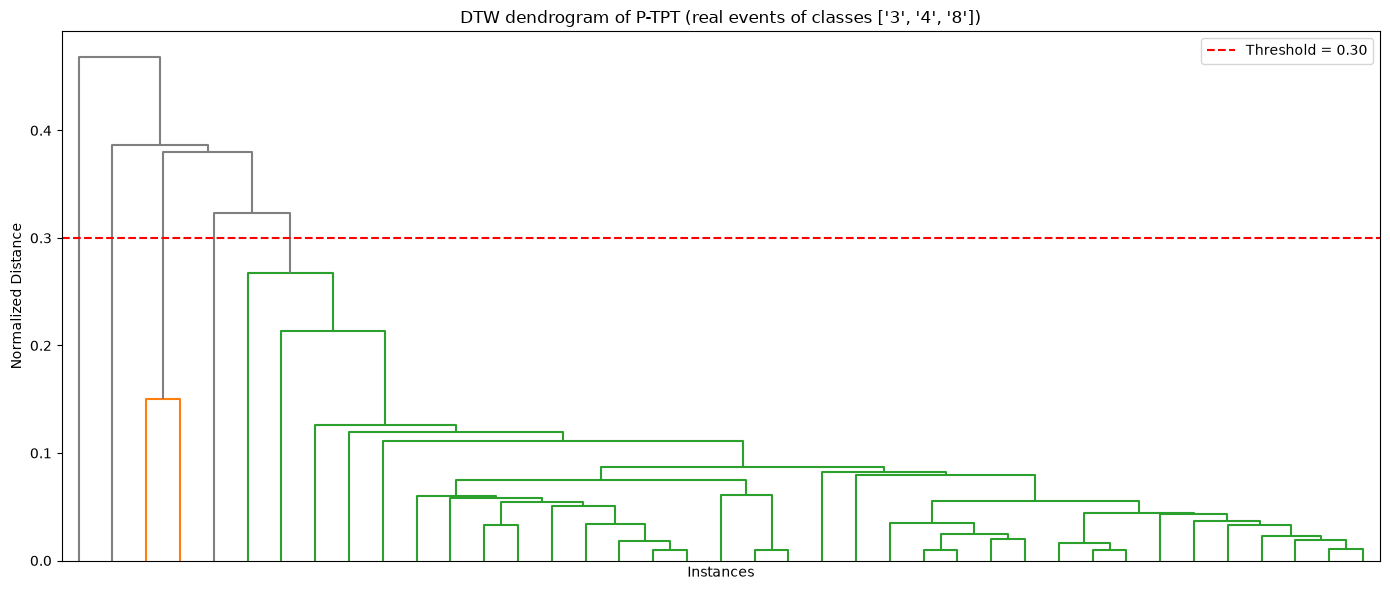

In [2]:
# ============================================================
# TOOLKIT FIRST: DTW + HIERARCHICAL CLUSTERING OF REAL EVENTS
# ============================================================
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.metrics import adjusted_rand_score
from sklearn.pipeline import Pipeline

from ThreeWToolkit.clustering import (
    DistanceComputer,
    HierarchicalClusterer,
    InstanceQualityFilter,
    TimeSeriesResampler,
    TimeSeriesScaler,
)
from ThreeWToolkit.core.base_clustering import (
    DistanceMatrixConfig,
    HierarchicalClusteringConfig,
    InstanceQualityConfig,
    ResamplingConfig,
    TimeSeriesScalingConfig,
)
from ThreeWToolkit.core.enums import DistanceMetricEnum
from ThreeWToolkit.data_visualization import DendrogramPlot
from ThreeWToolkit.dataset import ParquetDataset, ParquetDatasetConfig

VARIABLE = "P-TPT"
EVENTS_PER_CLASS = 15
classes_int = [int(c) for c in TARGET_CLASSES]

dataset_args = dict(
    path="../../dataset/",
    event_type=["real"],
    target_class=classes_int,
    columns=[VARIABLE],
    target_column=None,
)

# Keep the first EVENTS_PER_CLASS real events of each class
chosen, per_class = [], Counter()
for event_file in ParquetDataset(ParquetDatasetConfig(**dataset_args)).files_events:
    cls = int(event_file.parent.name)
    if per_class[cls] < EVENTS_PER_CLASS:
        chosen.append(event_file)
        per_class[cls] += 1
event_classes = [int(f.parent.name) for f in chosen]

subset = ParquetDataset(ParquetDatasetConfig(**dataset_args, split="list", file_list=chosen))
series = subset.load_instances_by_variable([VARIABLE])[VARIABLE]

# 1. Quality filter, then 2-5. the clustering pipeline
quality = InstanceQualityFilter(InstanceQualityConfig(max_nan_ratio=0.2, max_frozen_ratio=0.95))
clean_series = quality.fit_transform(series)
kept_classes = [event_classes[i] for i in quality.kept_indices_]

pipeline = Pipeline(
    [
        ("resample", TimeSeriesResampler(ResamplingConfig(step_size=100, step_method="slice"))),
        ("scaler", TimeSeriesScaler(TimeSeriesScalingConfig())),
        ("dtw", DistanceComputer(DistanceMatrixConfig(metric=DistanceMetricEnum.DTW, n_jobs=-1))),
        ("clusterer", HierarchicalClusterer(HierarchicalClusteringConfig())),
    ]
)
pipeline.fit(clean_series)
clusterer = pipeline.named_steps["clusterer"]

print(f"Events: {len(series)} loaded, {len(clean_series)} kept | classes: {dict(Counter(kept_classes))}")
for threshold in (0.2, 0.3, 0.4):
    groups = clusterer.get_clusters_at_threshold(threshold)
    print(
        f"   threshold {threshold}: {len(set(groups))} clusters | "
        f"adjusted Rand vs fault class = {adjusted_rand_score(kept_classes, groups):.3f}"
    )

fig, ax = DendrogramPlot(
    clusterer.linkage_matrix_,
    threshold=0.3,
    title=f"DTW dendrogram of {VARIABLE} (real events of classes {TARGET_CLASSES})",
).plot()
plt.show()

### From events to windows: the algorithms of the book

Next we change the question. Instead of ordering events by DTW similarity, we cluster **fixed-length series** (500 points, all sensors) with K-means, MeanShift and DBSCAN, and score them against the known classes with the silhouette and the adjusted Rand index. These algorithms are not in the toolkit and are implemented in `src/clustering_utils.py`.

## 📊 Complete Data Loading Strategy

### Why Use Complete 3W Data for Clustering?

**Different from Previous Notebooks**: Here we use **complete time series** directly from the 3W dataset, not windowed data.

**Key Differences**:
- **Fixed Length**: Resize all time series to exactly 500 points
- **Direct Analysis**: Each complete sensor reading sequence becomes one data point
- **Class Focus**: Analyze specific fault classes (3, 4, 8) for comparison

**Clustering Context**: 
- Each row = one complete oil well operation sequence
- Goal: Discover natural groupings in operational patterns
- Unsupervised: We ignore class labels during clustering

In [3]:
# ============================================================
# LOAD Complete 3W DATASET
# ============================================================

print("Loading Complete 3W Dataset for Clustering Analysis")
print("=" * 55)

try:
    # Initialize data persistence and load complete data
    persistence = DataPersistence(base_dir=config.PROCESSED_DATA_DIR, verbose=False)
    complete_data_dir = os.path.join(persistence.cv_splits_dir, "complete")

    if not os.path.exists(complete_data_dir):
        raise FileNotFoundError(
            f"Complete data directory not found: {complete_data_dir}"
        )

    # Load and process data using utility class
    start_time = time.time()
    complete_data_result = data_loader.load_complete_data(
        persistence, complete_data_dir
    )
    load_time = time.time() - start_time

    # Extract and filter data for target classes
    X_original = complete_data_result["X_original"]
    y_labels = complete_data_result["y_labels"]
    file_info = complete_data_result["file_info"]
    fold_used = complete_data_result["fold_used"]

    # Determine available classes and filter for analysis
    available_classes = sorted(np.unique(y_labels))
    existing_classes = [cls for cls in TARGET_CLASSES if cls in available_classes]

    # Use first 3 available classes if target classes don't exist
    if not existing_classes:
        existing_classes = (
            available_classes[:3] if len(available_classes) >= 3 else available_classes
        )
        print(f"⚠️ Target classes not found, using: {existing_classes}")

    # Filter data to selected classes
    class_mask = np.isin(y_labels, existing_classes)
    X_original = X_original[class_mask]
    y_labels = y_labels[class_mask]
    file_info = [file_info[i] for i, mask in enumerate(class_mask) if mask]

    # Display summary
    unique_classes, counts = np.unique(y_labels, return_counts=True)
    print("\n✅ Data Loading Complete!")
    print(
        f"   • Total samples: {len(X_original)} | Features: {X_original.shape[1]} | Classes: {len(unique_classes)}"
    )
    print(f"   • Load time: {load_time:.2f}s | Source: {fold_used}")
    print(f"   • Class distribution: {dict(zip(unique_classes, counts))}")

    # Store for subsequent cells
    clustering_data = {
        "X_original": X_original,
        "y_labels": y_labels,
        "file_info": file_info,
        "config": {
            "target_length": TARGET_LENGTH,
            "max_files_per_class": MAX_FILES_PER_CLASS,
            "sampling_enabled": ENABLE_SAMPLING,
            "fold_used": fold_used,
        },
    }

except Exception as e:
    print(f"❌ Error loading data: {str(e)}")
    print("💡 Check if 3W dataset is properly extracted and accessible")
    clustering_data = None

Loading Complete 3W Dataset for Clustering Analysis
Loading Complete 3W Dataset for Clustering Analysis
Using fold_1 for clustering analysis

Loading train_data...



Loading test_data...



✅ Data Loading Complete!
   • Total samples: 144 | Features: 1500 | Classes: 3
   • Load time: 1.55s | Source: fold_1
   • Class distribution: {np.str_('3'): np.int64(50), np.str_('4'): np.int64(50), np.str_('8'): np.int64(44)}


## ⚙️ Data Preprocessing for Clustering

### Why Preprocessing Matters for Clustering

**Scaling Issues**: Different sensors have different ranges (pressure vs temperature)
- Without scaling: High-range sensors dominate distance calculations
- Solution: StandardScaler and MinMaxScaler

**Dimensionality Challenge**: 500-point time series = very high dimensions
- Problem: "Curse of dimensionality" affects clustering quality
- Solution: PCA to reduce dimensions while preserving variance

**Multiple Representations**: We prepare several data versions for comparison
- Scaled, normalized, and PCA-reduced variants
- Best clustering method may prefer different preprocessing

In [4]:
# ============================================================
# DATA PREPROCESSING SETUP
# ============================================================

print("Data Preparation for Clustering Analysis")
print("=" * 45)

# Check if we have loaded data from previous cell
if "clustering_data" in locals() and clustering_data is not None:
    # Import preprocessing utilities
    from src.clustering_utils import ClusteringPreprocessor
    import warnings

    warnings.filterwarnings("ignore")

    # Extract complete data
    X_original = clustering_data["X_original"]
    y_labels = clustering_data["y_labels"]
    file_info = clustering_data["file_info"]

    print("Complete Data Overview:")
    print(f"   • Data shape: {X_original.shape}")
    print(f"   • Classes: {sorted(np.unique(y_labels))}")
    print(f"   • Total samples: {len(X_original)}")

    # Initialize preprocessor
    preprocessor = ClusteringPreprocessor()

    print("\nPreprocessor initialized. Ready for data preparation.")

else:
    print("No data available for preprocessing")
    print("   Please run the previous cells first to load complete 3W data")
    clustering_data = None

Data Preparation for Clustering Analysis
Complete Data Overview:
   • Data shape: (144, 1500)
   • Classes: [np.str_('3'), np.str_('4'), np.str_('8')]
   • Total samples: 144

Preprocessor initialized. Ready for data preparation.


In [5]:
# ============================================================
# APPLY DATA PREPROCESSING
# ============================================================

if "preprocessor" in locals() and preprocessor is not None:
    print("Applying data preprocessing transformations...")

    # Prepare data with scaling and dimensionality reduction
    processed_data = preprocessor.prepare_data(X_original)

    # Extract processed datasets
    X_scaled = processed_data["X_scaled"]
    X_normalized = processed_data["X_normalized"]
    X_pca_2d = processed_data["X_pca_2d"]
    pca_model = processed_data["pca_model"]
    variance_info = processed_data["variance_info"]

    print("\nPreprocessed Data Summary:")
    print(f"   • Original: {X_original.shape}")
    print(f"   • StandardScaled: {X_scaled.shape}")
    print(f"   • MinMax Normalized: {X_normalized.shape}")
    print(f"   • PCA (2D visualization): {X_pca_2d.shape}")

    # Update clustering_data with processed datasets
    clustering_data.update(processed_data)
    clustering_data["y_labels"] = y_labels
    clustering_data["file_info"] = file_info


else:
    print("Preprocessor not available. Please run the previous cell first.")
    clustering_data = None

Applying data preprocessing transformations...
Data Preparation for Clustering Analysis

Preprocessed Data Summary:
   • Original: (144, 1500)
   • StandardScaled: (144, 1500)
   • MinMax Normalized: (144, 1500)
   • PCA (2D visualization): (144, 2)


## 📈 Data Overview and PCA Visualization

### Understanding Your Data Before Clustering

**PCA Visualization**: Shows how much information is captured in lower dimensions
- First few components capture most variance

**Class Distribution**: See how known fault types are distributed
- Remember: clustering ignores these labels
- We'll compare clustering results against known classes later

**Dimensionality Trade-off**: 
- Too many dimensions: clustering becomes unreliable
- Too few dimensions: lose important patterns

Creating Data Overview Visualizations...


2026-11-05 17:26:33,843 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-05 17:26:33,847 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


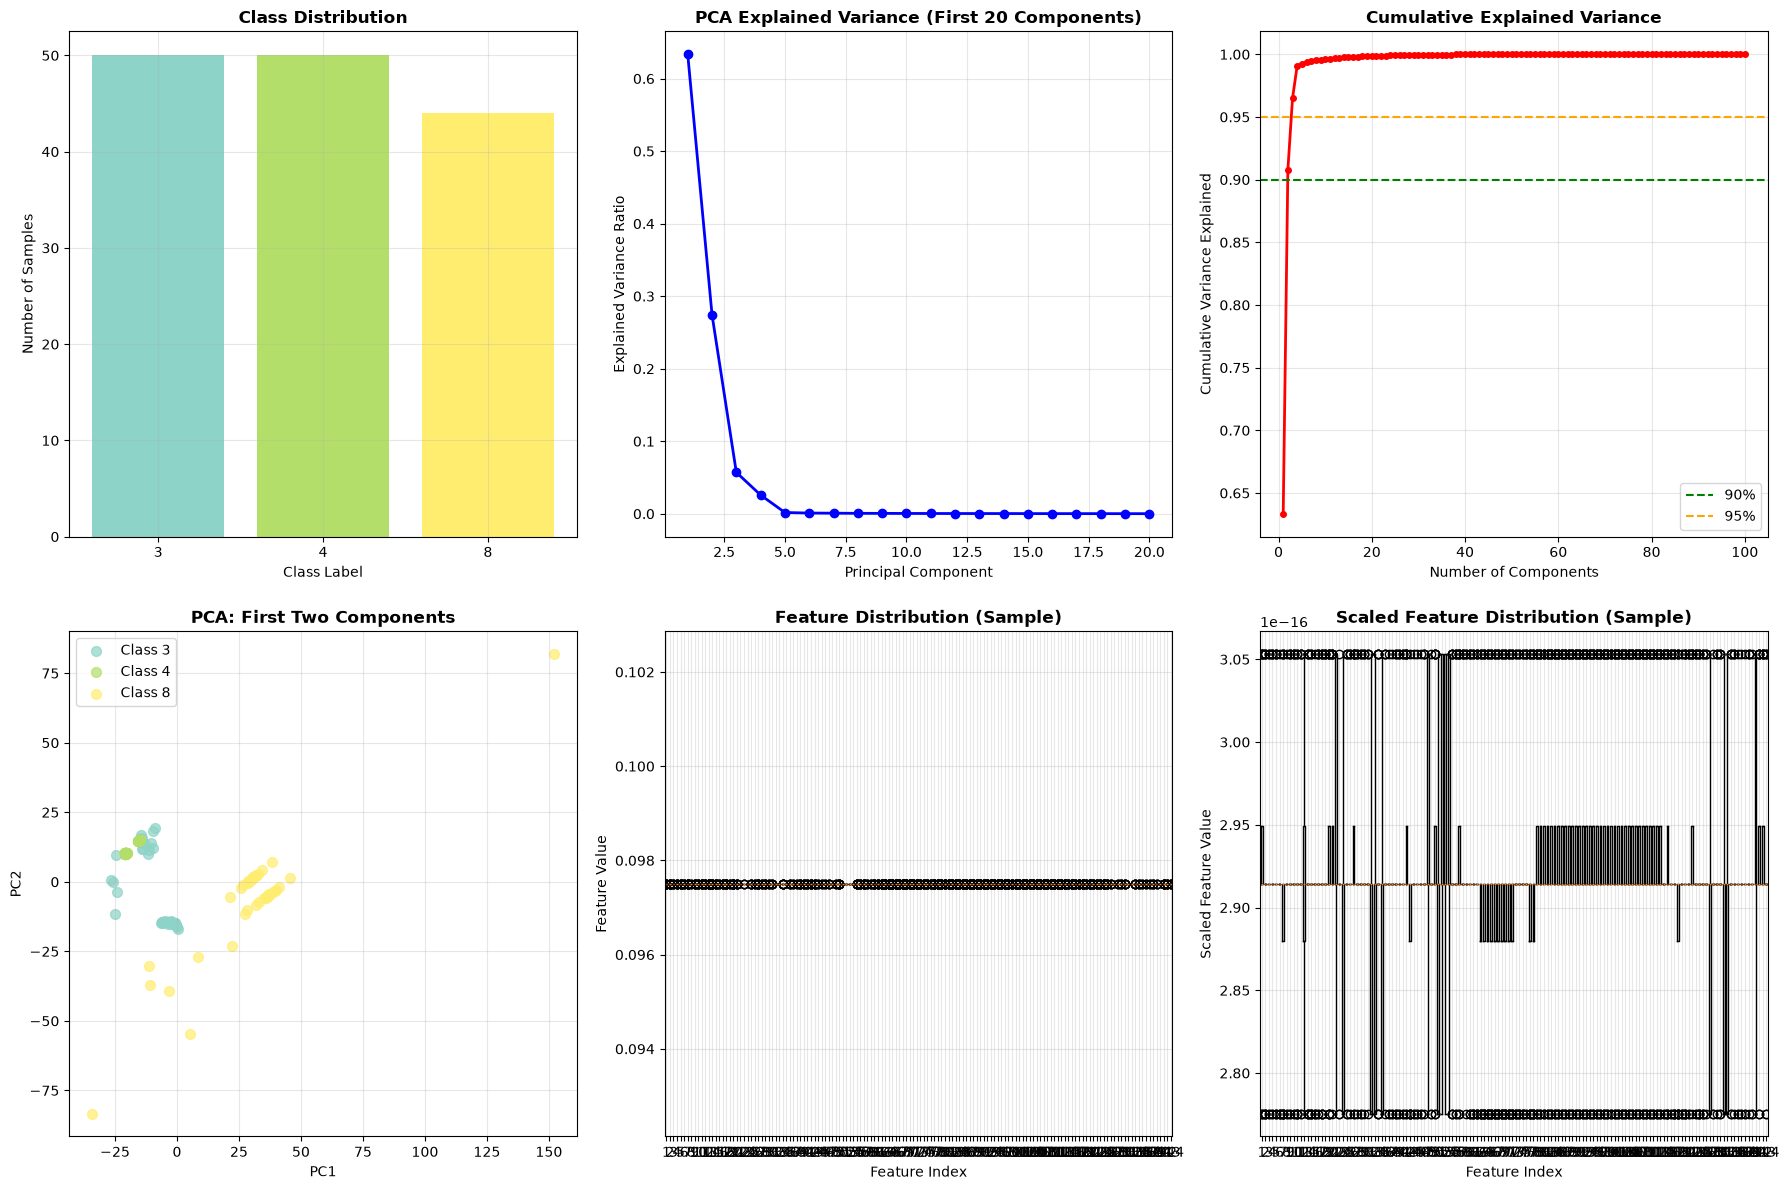

Data overview visualization complete!


In [6]:
# ============================================================
# DATA OVERVIEW VISUALIZATION
# ============================================================

if clustering_data is not None:
    print("Creating Data Overview Visualizations...")

    # Import visualization utilities
    from src.clustering_visualization import ClusteringVisualizer

    # Create visualizer
    visualizer = ClusteringVisualizer()

    # Create data overview plots
    visualizer.plot_data_overview(
        X_original=clustering_data["X_original"],
        X_scaled=clustering_data["X_scaled"],
        y_labels=clustering_data["y_labels"],
        pca_model=clustering_data["pca_model"],
        X_pca_2d=clustering_data["X_pca_2d"],
    )

    print("Data overview visualization complete!")

else:
    print("No clustering data available for visualization")
    print("   Please run the previous cells first")

## Clustering Theory Deep Dive

### **K-means Clustering Algorithm**

**Mathematical Foundation:**
K-means aims to minimize the Within-Cluster Sum of Squares (WCSS):

$$\text{WCSS} = \sum_{i=1}^{k} \sum_{x \in C_i} ||x - \mu_i||^2$$

Where:
- $k$ = number of clusters
- $C_i$ = cluster $i$
- $\mu_i$ = centroid of cluster $i$
- $||x - \mu_i||^2$ = squared Euclidean distance

**Algorithm Steps:**
1. **Initialize**: Randomly place $k$ centroids
2. **Assignment**: Assign each point to nearest centroid
3. **Update**: Recalculate centroids as cluster means
4. **Repeat**: Until convergence (centroids stop moving)

**Key Properties:**
- **Complexity**: $O(nkt)$ where $n$=points, $k$=clusters, $t$=iterations
- **Assumptions**: Spherical clusters, similar sizes, equal variance
- **Convergence**: Guaranteed to local minimum (not global)

**Parameter Selection:**
- **Elbow Method**: Find "elbow" in WCSS vs $k$ plot
- **Silhouette Analysis**: Measure cluster cohesion and separation
- **Gap Statistic**: Compare with random data clustering

**Strengths & Limitations:**
- ✅ **Pros**: Simple, fast, scalable, interpretable
- ❌ **Cons**: Need to specify $k$, sensitive to initialization, assumes spherical clusters

In [7]:
# ============================================================
# K-MEANS CLUSTERING ANALYSIS - SCALED DATA
# ============================================================

print("🚀 K-MEANS CLUSTERING ANALYSIS - Using Scaled Data for Clustering")
print("=" * 70)

# Import the KMeansAnalyzer class
from src.clustering_utils import KMeansAnalyzer

# Initialize analyzer
kmeans_analyzer = KMeansAnalyzer(k_range=range(2, 16))

# Run complete analysis using the extracted method
kmeans_results = kmeans_analyzer.run_kmeans_complete_analysis(
    X_scaled=clustering_data["X_scaled"],
    X_pca_50=clustering_data["X_pca_50"],
    analysis_type="scaled",
    clustering_data=clustering_data,
    visualizer=visualizer,
)

print("\n📊 Analysis Summary:")
print(f"   • Data Type: {kmeans_results['data_description']}")
print(f"   • Optimal K: {kmeans_results['optimal_k']}")
print(f"   • Silhouette Score: {kmeans_results['silhouette_score']:.3f}")
print(f"   • Number of Clusters: {kmeans_results['n_clusters']}")
print(f"   • Data Shape: {kmeans_results['clustering_data_shape']}")

# Store results for later use
optimal_k_scaled = kmeans_results["optimal_k"]
best_model = kmeans_results["best_model"]
optimal_labels = kmeans_results["labels"]

🚀 K-MEANS CLUSTERING ANALYSIS - Using Scaled Data for Clustering
🚀 Running Complete K-means Analysis (SCALED)
📊 Step 1: Finding optimal K using Scaled data...
K-means: Finding Optimal K (using SCALED data for clustering)
Testing K=2... OK
Testing K=3... 

OK
Testing K=4... OK
Testing K=5... OK
Testing K=6... 

OK
Testing K=7... OK
Testing K=8... 

OK
Testing K=9... OK
Testing K=10... 

OK
Testing K=11... OK
Testing K=12... 

OK
Testing K=13... OK
Testing K=14... 

OK
Testing K=15... OK
   ✅ Optimal K found: 6
🎯 Step 2: Training final model with K=6...
   ✅ Model trained successfully
   📈 Silhouette Score: 0.738
   📊 Inertia: 8699.47
   🎯 Clusters Found: 6
🎉 Complete K-means analysis finished!
------------------------------------------------------------

📊 Analysis Summary:
   • Data Type: Scaled
   • Optimal K: 6
   • Silhouette Score: 0.738
   • Number of Clusters: 6
   • Data Shape: (144, 1500)


## 🔍 K-means Parameter Optimization

### The Critical K Selection Problem

**Challenge**: K-means requires you to specify the number of clusters beforehand
- Too few clusters: Over-generalization, lose important patterns
- Too many clusters: Over-segmentation, noise becomes clusters

**Solution Methods**:
- **Elbow Method**: Find the "bend" in the error reduction curve
- **Silhouette Analysis**: Measure how well-separated clusters are
- **Domain Knowledge**: We expect ~3 clusters (fault classes 3, 4, 8)

**Data Comparison**: Test both scaled and PCA-reduced data
- Different preprocessing may reveal different optimal K values

> 📖 **In the book — Chapter 6, §*K-means* and Chapter 9.** In an open world, **K is exactly the quantity that is not known**: it is the number of *new* classes. Chapter 9 solves it by training a random forest to *predict* K from eight characteristics of the set being clustered (number of points, silhouette, Davies-Bouldin, Calinski-Harabasz, inertia and three geometric descriptors). Here, with a known set of classes, you will see the other side of the problem: **the K suggested by the indices rarely coincides with the number of classes**.

In [8]:
# ============================================================
# K-MEANS CLUSTERING: FINAL RESULTS AND EVALUATION
# ============================================================

if "kmeans_results" in locals() and kmeans_results is not None:
    # Import evaluation utilities
    from src.clustering_utils import ClusteringEvaluator

    # Create evaluator and run comprehensive K-means evaluation
    evaluator = ClusteringEvaluator()
    kmeans_results = evaluator.evaluate_kmeans_final_results(
        kmeans_results=kmeans_results, clustering_data=clustering_data
    )

else:
    print("K-means results not available")
    print("   Please run the K-means clustering analysis cell first")

K-means Clustering: Final Results and Evaluation
Applying optimal K-means clustering...
   • Method: Scaled
   • Optimal K: 6
   • PCA usage: Visualization only (2D plots)

K-means Performance Evaluation:
   • Silhouette Score: 0.738
   • Adjusted Rand Index: 0.503
   • WCSS: 8.70e+03

Cluster Size Distribution:
   • Cluster 0: 69 samples (47.9%)
   • Cluster 1: 20 samples (13.9%)
   • Cluster 2: 33 samples (22.9%)
   • Cluster 3: 1 samples (0.7%)
   • Cluster 4: 16 samples (11.1%)
   • Cluster 5: 5 samples (3.5%)

K-means clustering analysis complete!
✅ Clustering performed on: SCALED data ((144, 1500))
✅ PCA used for: 2D visualization only


Creating K-means Analysis Visualizations...


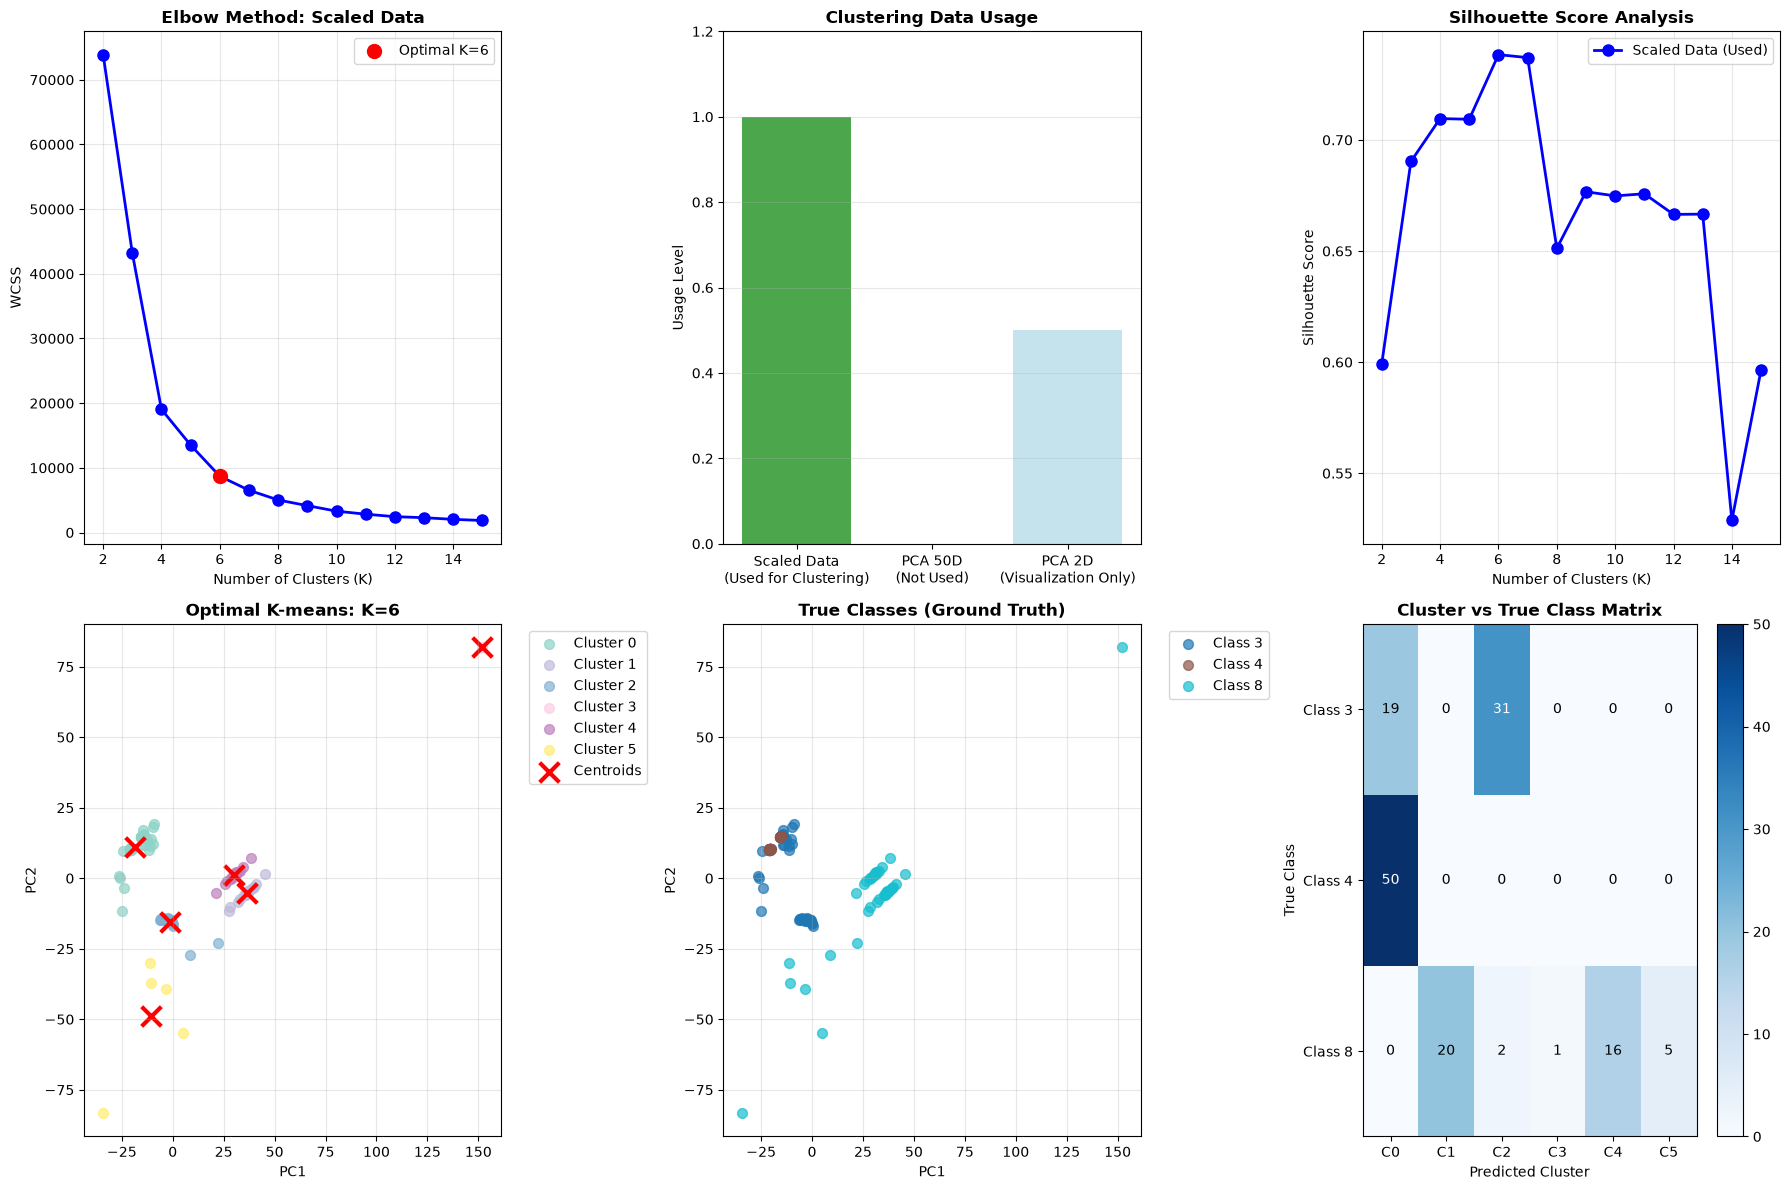

K-means visualization complete!
Note: PCA used only for 2D visualization, clustering performed on scaled data


In [9]:
# ============================================================
# K-MEANS VISUALIZATION
# ============================================================

if "kmeans_results" in locals() and kmeans_results is not None:
    print("Creating K-means Analysis Visualizations...")

    # Create K-means analysis plots
    visualizer.plot_kmeans_analysis(
        k_range=range(2, 16),
        results=kmeans_results["elbow_analysis"],
        optimal_k_scaled=kmeans_results["optimal_k_scaled"],
        optimal_k_pca=None,  # No longer using PCA for clustering
        X_pca_2d=clustering_data["X_pca_2d"],
        optimal_labels=kmeans_results[
            "labels"
        ],  # Fixed: use "labels" instead of "optimal_labels"
        centroids_2d=kmeans_results["centroids_2d"],
        y_true=clustering_data["y_labels"],
        n_clusters=kmeans_results[
            "optimal_k"
        ],  # Fixed: use "optimal_k" instead of "best_k"
    )

    print("K-means visualization complete!")
    print(
        "Note: PCA used only for 2D visualization, clustering performed on scaled data"
    )

else:
    print("K-means results not available for visualization")
    print("   Please run the K-means clustering cells first")

In [10]:
# ============================================================
# K-MEANS CLUSTERING: PCA 50D DATA ANALYSIS
# ============================================================

if clustering_data is not None:
    print("K-means Clustering: PCA 50D Data Analysis")
    print("=" * 45)

    # Extract PCA 50D preprocessed data (if available)
    if "X_pca_50" in clustering_data:
        X_pca_50 = clustering_data["X_pca_50"]
    else:
        # Fallback: create PCA 50D if not available
        from sklearn.decomposition import PCA

        pca_50 = PCA(n_components=50, random_state=42)
        X_pca_50 = pca_50.fit_transform(clustering_data["X_scaled"])
        print("Generated PCA 50D data from scaled data")

    X_pca_2d = clustering_data["X_pca_2d"]
    y_true = clustering_data["y_labels"]

    print("K-means Analysis Setup (PCA 50D):")
    print(f"   • PCA 50D data (for clustering): {X_pca_50.shape}")
    print(f"   • PCA 2D (for visualization): {X_pca_2d.shape}")
    print(
        f"   • True classes: {len(np.unique(y_true))} classes {list(np.unique(y_true))}"
    )

    print("\n🎯 CLUSTERING STRATEGY (PCA 50D):")
    print("   • Using PCA 50D DATA for actual clustering")
    print(f"   • Reduced dimensions: {X_pca_50.shape[1]} features")
    print("   • All optimization based on PCA 50D data performance")

    # Initialize K-means analyzer for PCA data
    kmeans_analyzer_pca = KMeansAnalyzer(k_range=range(2, 16))

    print(
        "\nFinding optimal K using elbow method and silhouette analysis on PCA 50D data..."
    )

    # Find optimal K using PCA 50D data only
    results_pca, optimal_k_pca = kmeans_analyzer_pca.find_optimal_k(X_pca_50)

    # Get best model configuration (uses PCA 50D data)
    best_model_info_pca = kmeans_analyzer_pca.get_best_model(
        results_pca, optimal_k_pca, X_pca_50
    )

    print("\nOptimal K Selection Results (PCA 50D):")
    print(f"   • Optimal K (PCA 50D data): {optimal_k_pca}")
    print(f"   • Clustering performed on: {best_model_info_pca['best_data_type']}")
    print(f"   • True number of classes: {len(np.unique(y_true))}")
    print(f"   • Dimensions used: {X_pca_50.shape[1]} PCA components")

    # Store results for comparison
    kmeans_optimization_pca = {
        "results": results_pca,
        "optimal_k_pca": optimal_k_pca,
        "best_model_info": best_model_info_pca,
    }

    print("\nK-means parameter optimization (PCA 50D) complete!")

else:
    print("No clustering data available")
    print("   Please run the data preparation cells first")
    kmeans_optimization_pca = None

K-means Clustering: PCA 50D Data Analysis
K-means Analysis Setup (PCA 50D):
   • PCA 50D data (for clustering): (144, 50)
   • PCA 2D (for visualization): (144, 2)
   • True classes: 3 classes [np.str_('3'), np.str_('4'), np.str_('8')]

🎯 CLUSTERING STRATEGY (PCA 50D):
   • Using PCA 50D DATA for actual clustering
   • Reduced dimensions: 50 features
   • All optimization based on PCA 50D data performance

Finding optimal K using elbow method and silhouette analysis on PCA 50D data...
K-means: Finding Optimal K (using SCALED data for clustering)
Testing K=2... OK
Testing K=3... OK
Testing K=4... OK
Testing K=5... 

OK
Testing K=6... OK
Testing K=7... 

OK
Testing K=8... OK
Testing K=9... 

OK
Testing K=10... 

OK
Testing K=11... 

OK
Testing K=12... OK
Testing K=13... 

OK
Testing K=14... OK
Testing K=15... 

OK

Optimal K Selection Results (PCA 50D):
   • Optimal K (PCA 50D data): 6
   • Clustering performed on: Scaled Data
   • True number of classes: 3
   • Dimensions used: 50 PCA components

K-means parameter optimization (PCA 50D) complete!


In [11]:
# ============================================================
# K-MEANS CLUSTERING: PCA 50D FINAL RESULTS AND EVALUATION
# ============================================================

if "kmeans_optimization_pca" in locals() and kmeans_optimization_pca is not None:
    # Create evaluator and run comprehensive K-means PCA evaluation
    kmeans_results_pca = evaluator.evaluate_kmeans_pca_final_results(
        kmeans_optimization_pca=kmeans_optimization_pca,
        clustering_data=clustering_data,
        scaled_kmeans_results=kmeans_results if "kmeans_results" in locals() else None,
    )

else:
    print("K-means PCA optimization results not available")
    print("   Please run the K-means PCA parameter optimization cell first")
    kmeans_results_pca = None

K-means Clustering: PCA 50D Final Results and Evaluation
Applying optimal K-means clustering (PCA 50D)...
   • Method: Scaled Data (PCA 50D data)
   • Optimal K: 6
   • Feature dimensions: 50 PCA components

K-means Performance Evaluation (PCA 50D):
   • Silhouette Score: 0.739
   • Adjusted Rand Index: 0.503
   • WCSS: 8.70e+03

Cluster Size Distribution (PCA 50D):
   • Cluster 0: 69 samples (47.9%)
   • Cluster 1: 20 samples (13.9%)
   • Cluster 2: 33 samples (22.9%)
   • Cluster 3: 1 samples (0.7%)
   • Cluster 4: 16 samples (11.1%)
   • Cluster 5: 5 samples (3.5%)

K-means clustering analysis (PCA 50D) complete!
✅ Clustering performed on: PCA 50D data ((144, 50))
✅ Centroids available in: 2D PCA space for visualization

📊 COMPARISON: Scaled Data vs PCA 50D Data
   • Scaled Data   - K: 6, Silhouette: 0.738, ARI: 0.503
   • PCA 50D Data  - K: 6, Silhouette: 0.739, ARI: 0.503
   🏆 PCA 50D performs better (higher silhouette score)


Creating K-means PCA 50D Analysis Visualizations...


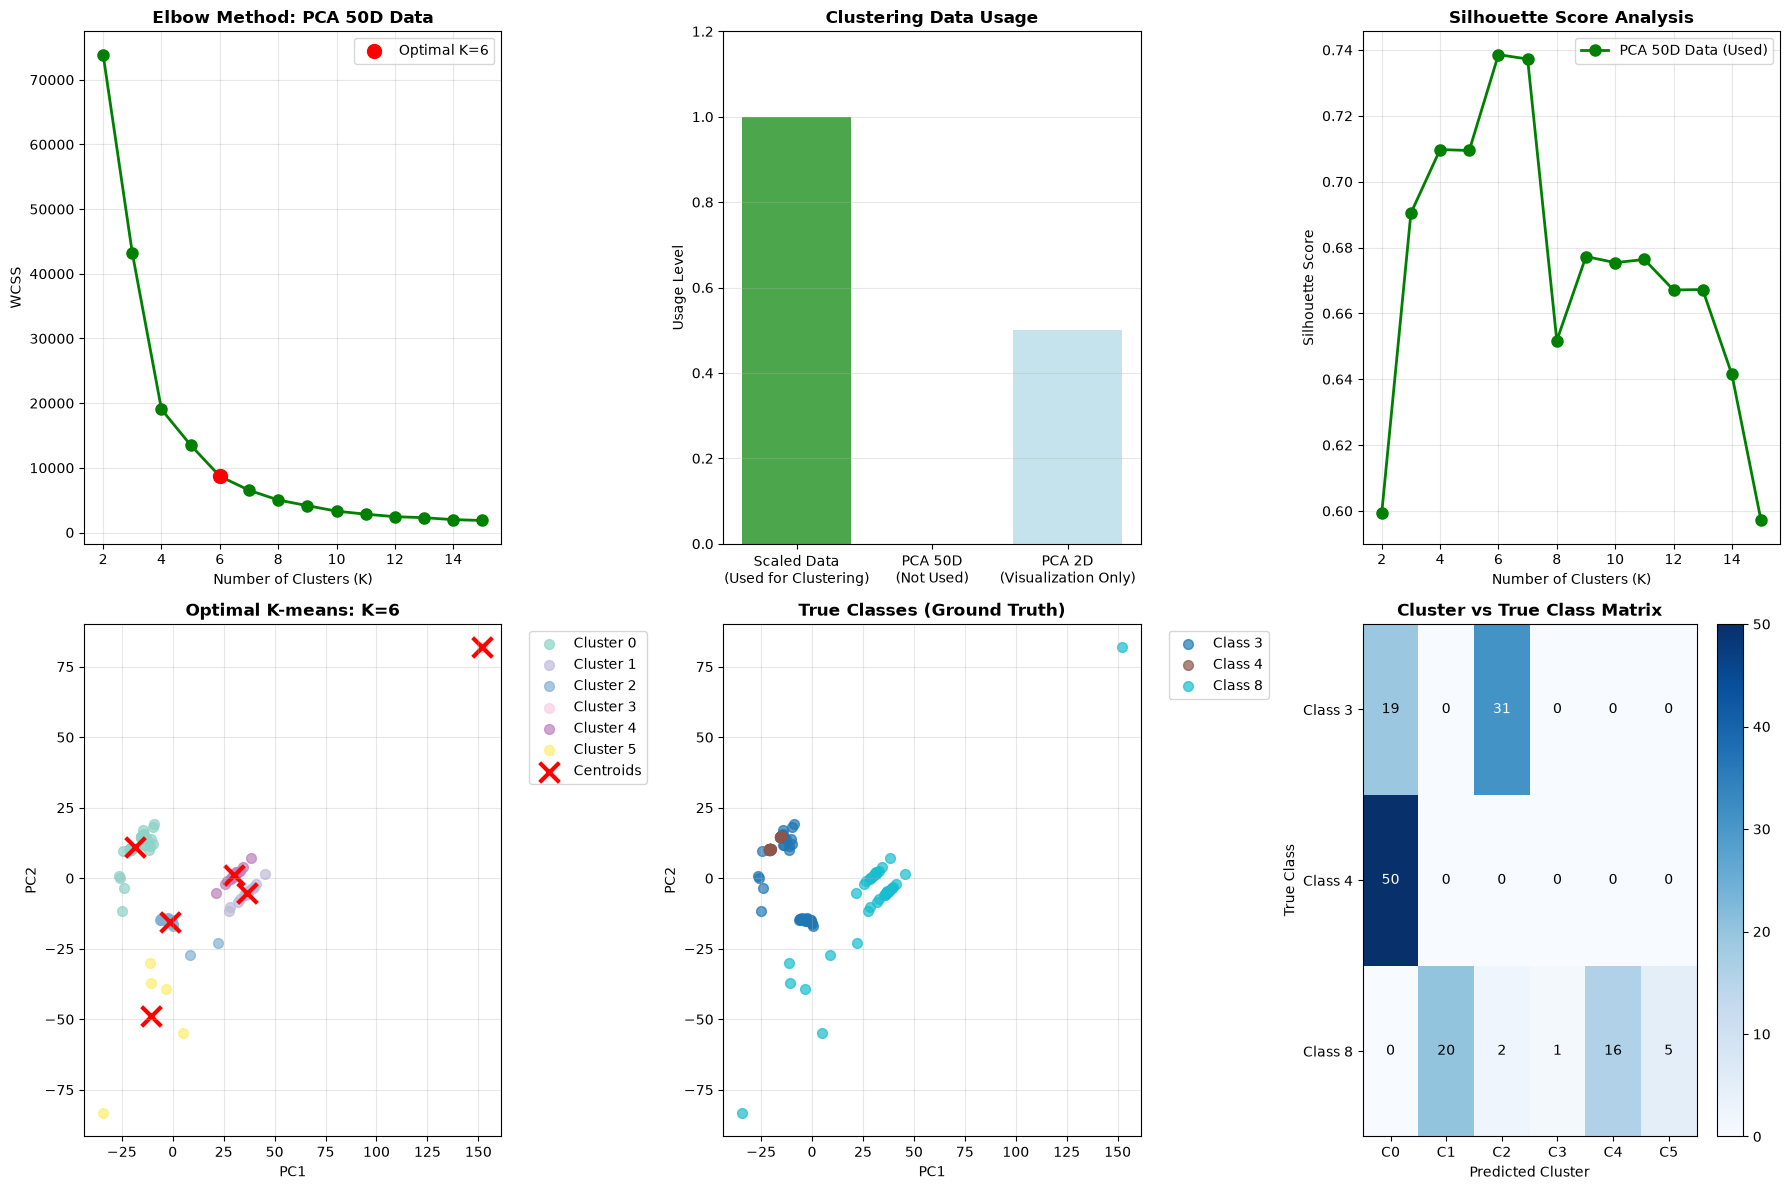

K-means PCA 50D visualization complete!
Note: Clustering performed on PCA 50D data, visualization in 2D PCA space


In [12]:
# ============================================================
# K-MEANS PCA 50D VISUALIZATION
# ============================================================

if "kmeans_results_pca" in locals() and kmeans_results_pca is not None:
    print("Creating K-means PCA 50D Analysis Visualizations...")

    # Create K-means analysis plots for PCA data
    visualizer.plot_kmeans_analysis(
        k_range=range(2, 16),
        results=kmeans_results_pca["elbow_analysis"],
        optimal_k_scaled=None,  # No scaled data in this analysis
        optimal_k_pca=kmeans_results_pca["optimal_k_pca"],
        X_pca_2d=clustering_data["X_pca_2d"],
        optimal_labels=kmeans_results_pca["optimal_labels"],
        centroids_2d=kmeans_results_pca["centroids_2d"],
        y_true=clustering_data["y_labels"],
        n_clusters=kmeans_results_pca["best_k"],
    )

    print("K-means PCA 50D visualization complete!")
    print("Note: Clustering performed on PCA 50D data, visualization in 2D PCA space")

else:
    print("K-means PCA results not available for visualization")
    print("   Please run the K-means PCA clustering cells first")

## 🎯 Mean Shift: Mode-Seeking Clustering

### Mean Shift's Unique Approach

**Centroid-Based**: Iteratively shifts cluster centers toward regions of higher density  
- Finds clusters without predefining their number  
- Works well for irregular or non-spherical clusters  

**Key Innovation**: Sliding window (kernel) moves toward data density peaks  
- Each point shifts toward the nearest high-density region (mode)  
- Automatically discovers the number of clusters  

**Parameters**:
- **Bandwidth**: Radius of the window (controls cluster granularity)

**High dimensions**: on the 1500-dimensional normalized data every point is used as a seed (`bin_seeding=False`) and the bandwidth is the estimated one. With `bin_seeding`, the grid seeds are farther than the bandwidth from every point and the result degenerates to a single cluster, whatever the bandwidth.

Mean Shift Clustering


📊 Creating Mean Shift Clustering Analysis & Comparison with Ground Truth
🔍 Available Mean Shift results: ['pca', 'normalized']



🔬 Computing metrics for PCA data...
📈 Mean Shift (PCA) Quality Metrics:
   • Clusters Found: 11
   • Ground Truth Classes: 3
   • Silhouette Score: 0.679
   • Adjusted Rand Index: 0.535
   • Normalized Mutual Info: 0.642
   • Homogeneity: 0.778
   • Completeness: 0.547
   • V-Measure: 0.642



🔬 Computing metrics for NORMALIZED data...
📈 Mean Shift (NORMALIZED) Quality Metrics:
   • Clusters Found: 12
   • Ground Truth Classes: 3
   • Silhouette Score: 0.755
   • Adjusted Rand Index: 0.522
   • Normalized Mutual Info: 0.634
   • Homogeneity: 0.760
   • Completeness: 0.544
   • V-Measure: 0.634


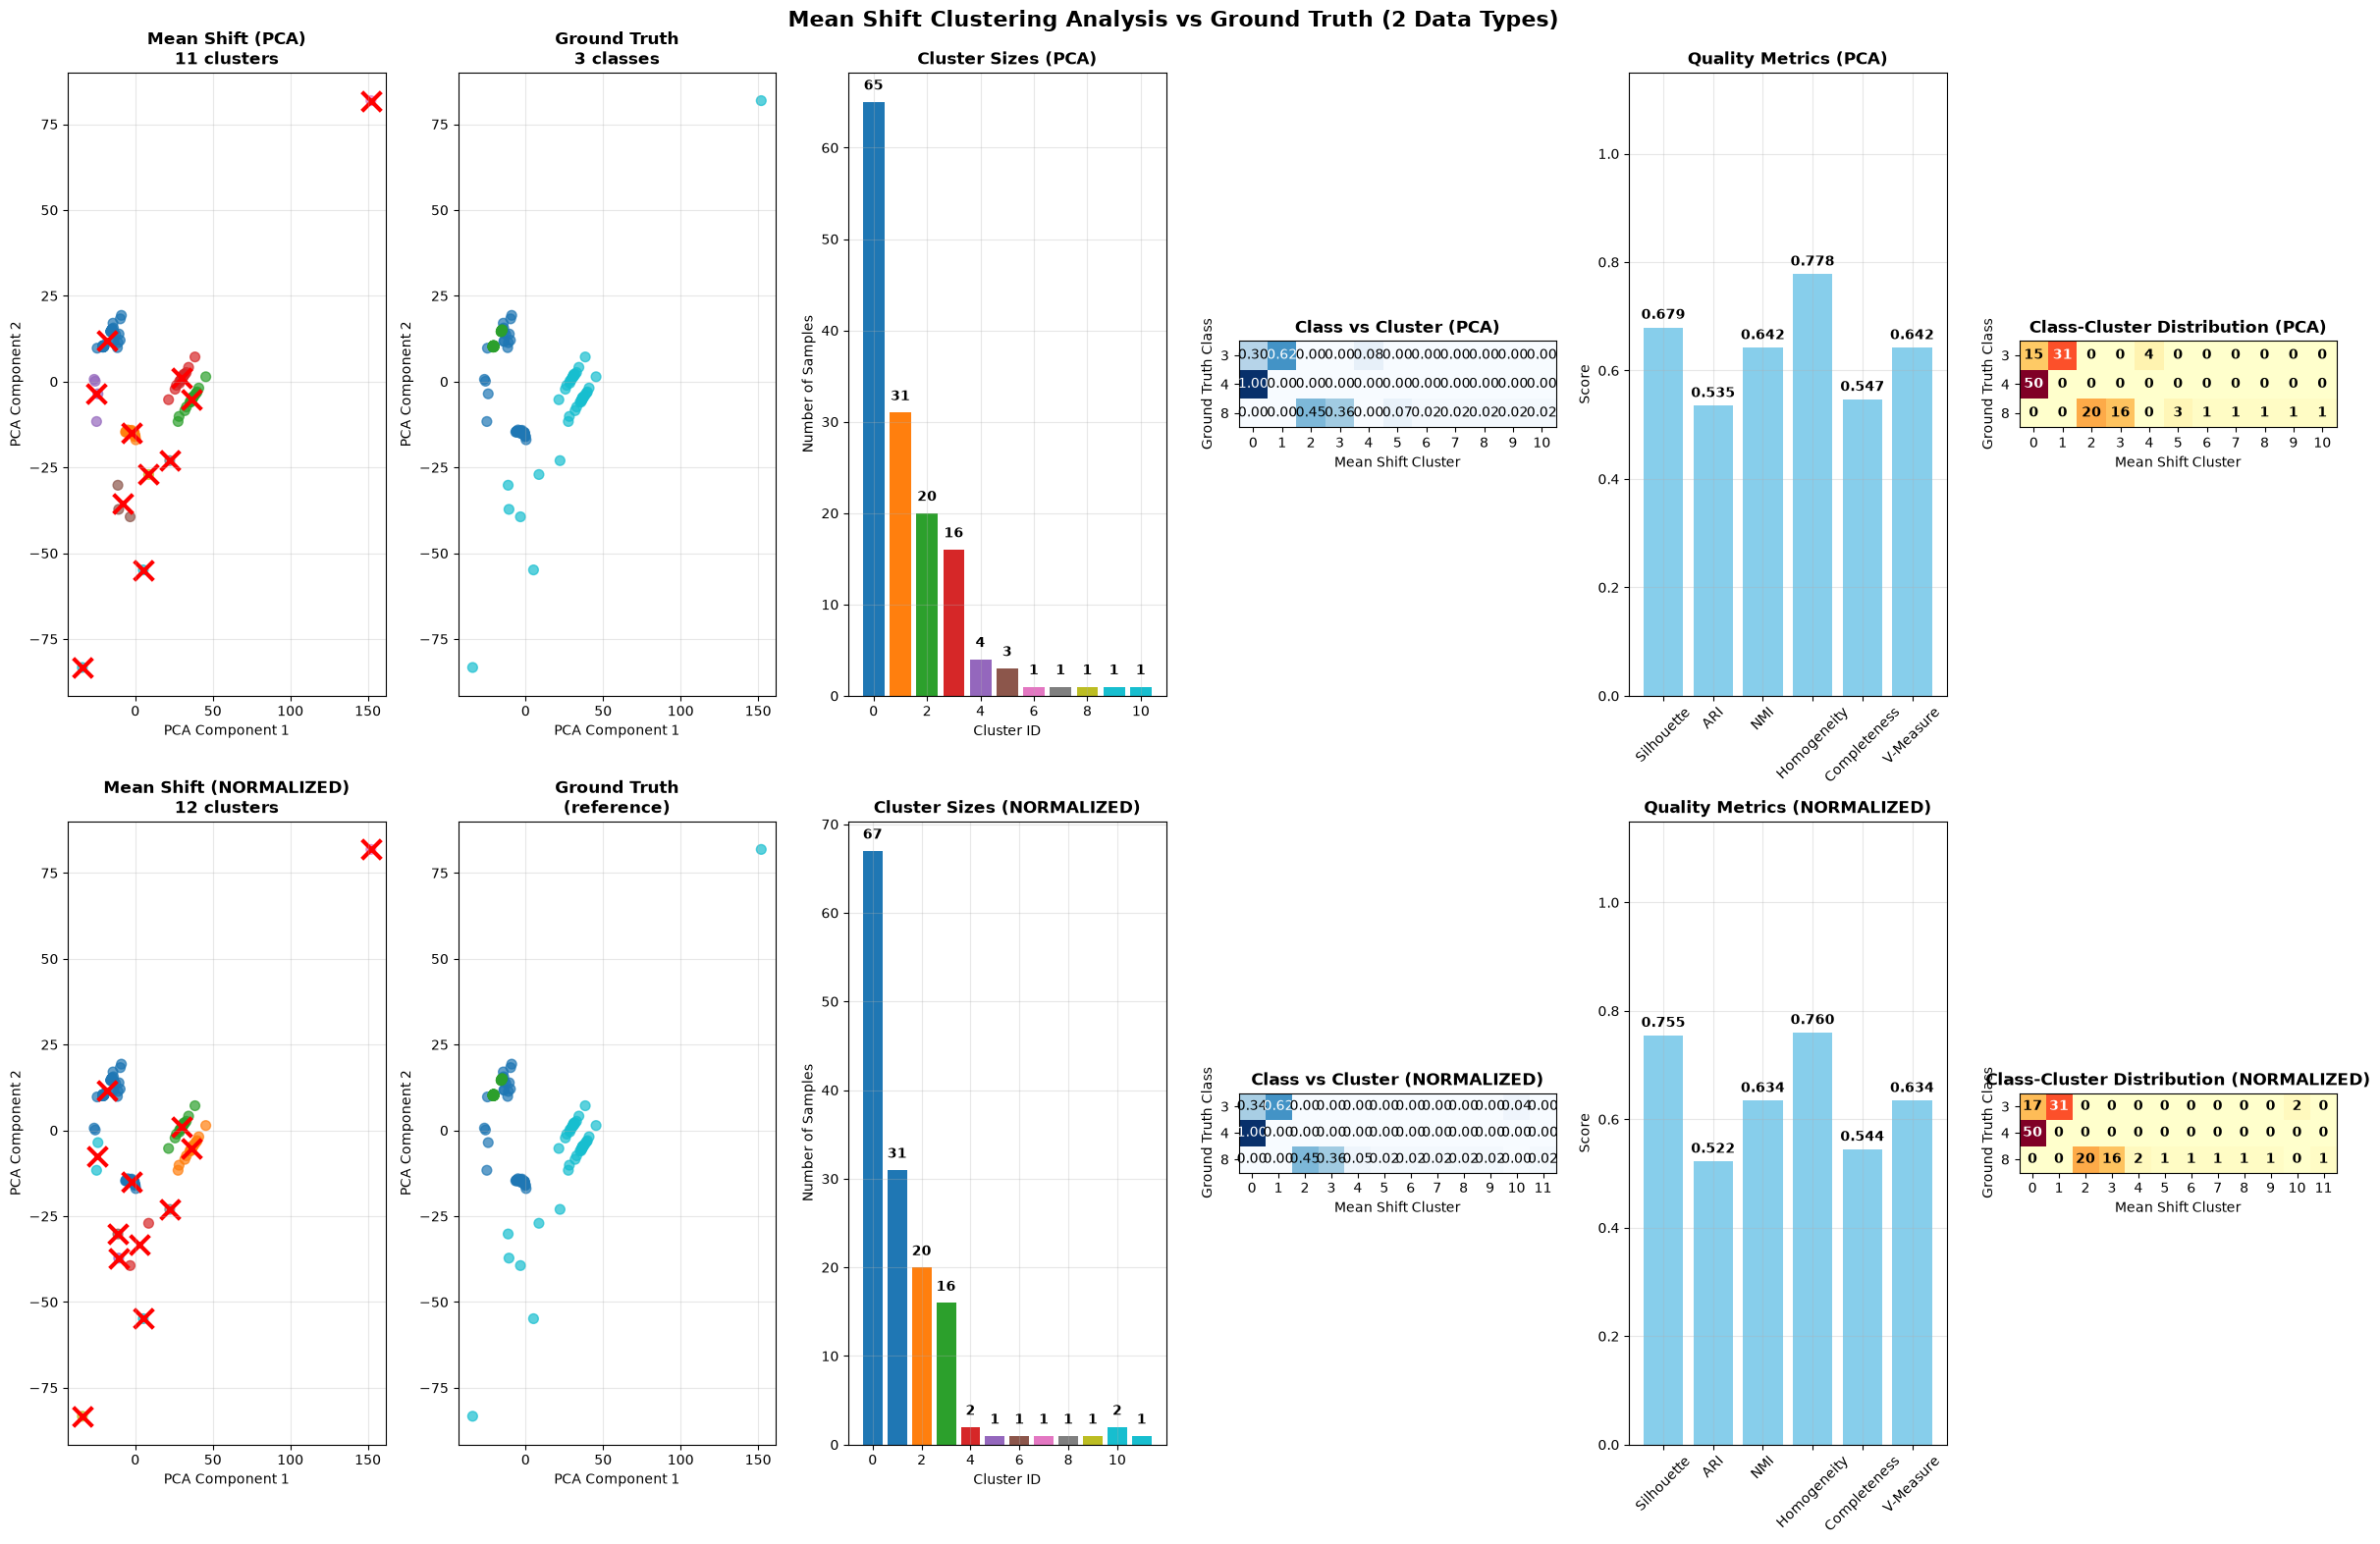


🎯 Mean Shift Clustering Comparison Summary:

📊 PCA Data Performance:
   • Clusters found: 11
   • Silhouette score: 0.679
   • Agreement with GT (ARI): 0.535
   ✅ Good agreement with ground truth
   ✅ Well-separated clusters

📊 NORMALIZED Data Performance:
   • Clusters found: 12
   • Silhouette score: 0.755
   • Agreement with GT (ARI): 0.522
   ✅ Good agreement with ground truth
   ✅ Well-separated clusters


In [13]:
# ============================================================
# MEAN SHIFT CLUSTERING
# ============================================================

# Import advanced clustering utilities
from src.clustering_utils import AdvancedClusteringAnalyzer

# Extract data for clustering
X_normalized = clustering_data["X_normalized"]
X_pca_50 = clustering_data["X_pca_50"]
X_pca_2d = clustering_data["X_pca_2d"]
y_true = clustering_data["y_labels"]

# Initialize advanced clustering analyzer
advanced_analyzer = AdvancedClusteringAnalyzer()

# Run Mean Shift clustering
meanshift_results = advanced_analyzer.run_mean_shift(X_pca_50, X_normalized)


# Use the extracted visualization method for clean, maintainable code
visualizer.plot_meanshift_analysis(
    meanshift_results=meanshift_results, clustering_data=clustering_data
)

## 🎯 DBSCAN: Density-Based Clustering

### DBSCAN's Unique Approach

**Density-Based**: Groups points in high-density regions, marks sparse areas as noise
- Perfect for real-world data with outliers
- Can find arbitrary cluster shapes (not just spherical)

**Key Innovation**: Automatic noise detection
- Points in low-density areas labeled as "noise"
- Robust to outliers and irregular patterns

**Parameters**:
- **ε (eps)**: Maximum distance for neighborhood
- **MinPts**: Minimum points to form a dense cluster

> 📖 **In the book — Chapter 6, §*DBSCAN*.** Labelling low-density points as *noise* is attractive in an open world, because rejecting is desirable — but in high-dimensional spaces the notion of density degrades and the amount of noise depends strongly on the radius ε: with the smallest ε of the grid searched below, 23 % to 38 % of the series of the normalized data are labelled as noise. Here ε is chosen by the silhouette (the noise points count as one more group), which leaves about 6 % of noise. That is why Chapter 9 uses DBSCAN only as a **comparison**, not as a component of the pipeline. Watch the noise ratio printed below, and compare the silhouette with the adjusted Rand index: compact groups are not necessarily the classes.

DBSCAN Clustering



DBSCAN Normalized Results:
   • Best eps: 2.8245
   • Best min_samples: 3
   • Clusters found: 4
   • Noise points: 9
   • Silhouette score: 0.824
DBSCAN Clustering

DBSCAN PCA 50D Results:
   • Best eps: 17.7157
   • Best min_samples: 3
   • Clusters found: 5
   • Noise points: 5
   • Silhouette score: 0.716

🎯 Running DBSCAN Comprehensive Analysis...
📊 Creating DBSCAN Clustering Analysis & Comparison with Ground Truth
🔍 Available DBSCAN results: ['normalized', 'pca']



🔬 Computing metrics for NORMALIZED data...
   • Parameters: eps=2.8245, min_samples=3
   • Clusters found: 4
   • Noise points: 9
📈 DBSCAN (NORMALIZED) Quality Metrics:
   • Clusters Found: 4
   • Noise Points: 9
   • Ground Truth Classes: 3
   • Silhouette Score: 0.824 (noise counted as a group)
   • Adjusted Rand Index: 0.523
   • Normalized Mutual Info: 0.649
   • Homogeneity: 0.731
   • Completeness: 0.583
   • V-Measure: 0.649

🔬 Computing metrics for PCA data...
   • Parameters: eps=17.7157, min_samples=3
   • Clusters found: 5
   • Noise points: 5
📈 DBSCAN (PCA) Quality Metrics:
   • Clusters Found: 5
   • Noise Points: 5
   • Ground Truth Classes: 3
   • Silhouette Score: 0.716 (noise counted as a group)
   • Adjusted Rand Index: 0.516
   • Normalized Mutual Info: 0.653
   • Homogeneity: 0.743
   • Completeness: 0.583
   • V-Measure: 0.653


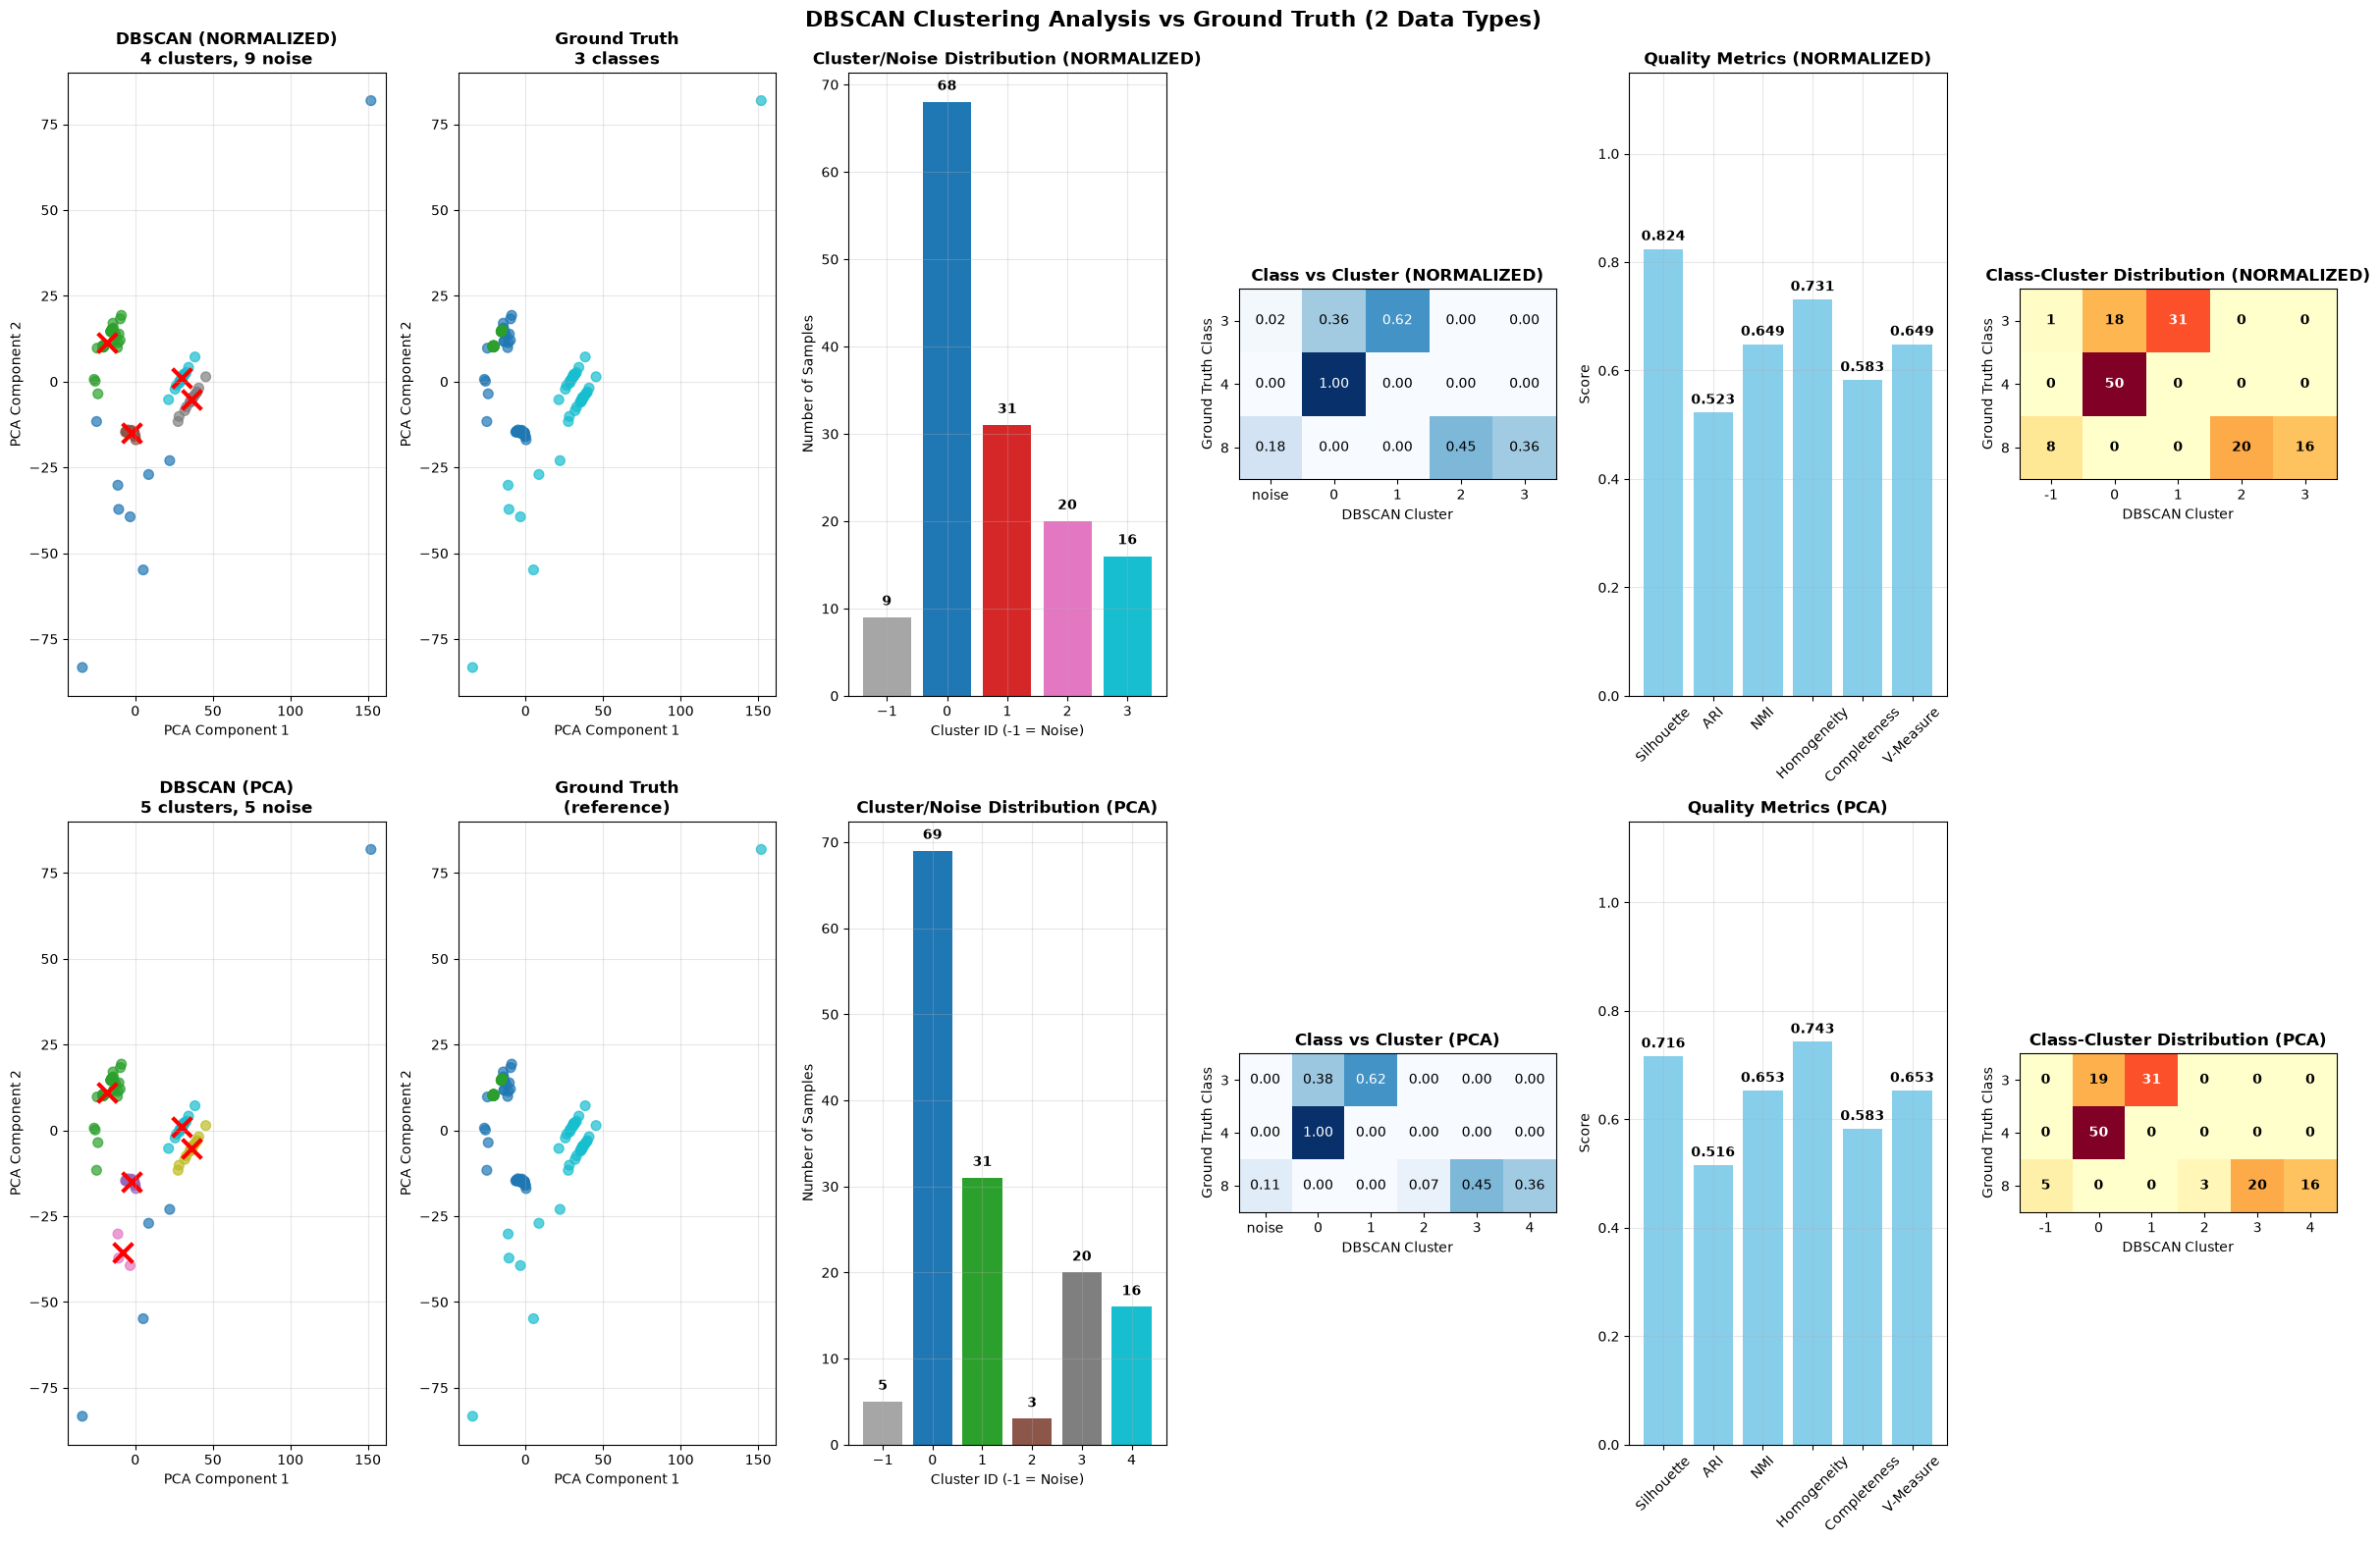


🎯 DBSCAN Clustering Comparison Summary:

📊 NORMALIZED Data Performance:
   • Clusters found: 4
   • Noise points: 9 (6.2%)
   • Silhouette score: 0.824
   • Agreement with GT (ARI): 0.523
   ✅ Good agreement with ground truth
   ✅ Well-separated clusters

📊 PCA Data Performance:
   • Clusters found: 5
   • Noise points: 5 (3.5%)
   • Silhouette score: 0.716
   • Agreement with GT (ARI): 0.516
   ✅ Good agreement with ground truth
   ✅ Well-separated clusters

✅ DBSCAN analysis complete!
📊 Comparison shows performance on both normalized and PCA 50D data


In [14]:
# ============================================================
# DBSCAN CLUSTERING
# ============================================================

# Run DBSCAN clustering with parameter optimization
dbscan_results = advanced_analyzer.run_dbscan(X_normalized)

if dbscan_results is not None:
    print("\nDBSCAN Normalized Results:")
    print(f"   • Best eps: {dbscan_results['params']['eps']:.4f}")
    print(f"   • Best min_samples: {dbscan_results['params']['min_samples']}")
    print(f"   • Clusters found: {dbscan_results['n_clusters']}")
    print(f"   • Noise points: {dbscan_results['n_noise']}")
    print(f"   • Silhouette score: {dbscan_results['silhouette']:.3f}")

# Run DBSCAN clustering with parameter optimization PCA
dbscan_results_PCA = advanced_analyzer.run_dbscan(X_pca_50)

if dbscan_results_PCA is not None:
    print("\nDBSCAN PCA 50D Results:")
    print(f"   • Best eps: {dbscan_results_PCA['params']['eps']:.4f}")
    print(f"   • Best min_samples: {dbscan_results_PCA['params']['min_samples']}")
    print(f"   • Clusters found: {dbscan_results_PCA['n_clusters']}")
    print(f"   • Noise points: {dbscan_results_PCA['n_noise']}")
    print(f"   • Silhouette score: {dbscan_results_PCA['silhouette']:.3f}")

print("\n" + "=" * 60)
print("🎯 Running DBSCAN Comprehensive Analysis...")

# Use the extracted visualization method for clean, maintainable code
visualizer.plot_dbscan_analysis(
    dbscan_results_norm=dbscan_results,
    dbscan_results_pca=dbscan_results_PCA,
    clustering_data=clustering_data,
)

print("\n✅ DBSCAN analysis complete!")
print("📊 Comparison shows performance on both normalized and PCA 50D data")

## All the methods above in one table

Silhouette and adjusted Rand index were printed method by method. Here they are side by side, with the **accuracy of the Hungarian matching** (each class is matched to one cluster and the samples of the other clusters, and of the noise, count as errors) and with **references** to compare with:
- *K-means with K = 3*: the number of classes is told to the algorithm;
- *constant label*: always the largest class (what a model that ignores the data scores);
- *true classes*: the silhouette that the real classes have in the same space.

In [15]:
# ============================================================
# ONE TABLE FOR THE METHODS ABOVE, WITH SOMETHING TO COMPARE WITH
# ============================================================
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, silhouette_score

import pandas as pd
from src.clustering_utils import hungarian_accuracy

y = np.array([int(label) for label in clustering_data["y_labels"]])
X_scaled = clustering_data["X_scaled"]


def summarize(method, space, X, labels):
    labels = np.asarray(labels)
    n_groups = len(set(labels))
    return {
        "Method": method,
        "Space": space,
        "Clusters": n_groups - (1 if -1 in labels else 0),
        "Noise": int((labels == -1).sum()),
        "Silhouette": silhouette_score(X, labels) if n_groups > 1 else float("nan"),
        "Adjusted Rand": adjusted_rand_score(y, labels),
        "Accuracy": hungarian_accuracy(y, labels),
    }


rows = [
    summarize("K-means (K by silhouette)", "scaled", X_scaled, kmeans_results["labels"]),
    summarize("K-means (K by silhouette)", "PCA 50D", X_pca_50, kmeans_results_pca["optimal_labels"]),
    summarize("Mean Shift", "PCA 50D", X_pca_50, meanshift_results["pca"]["labels"]),
    summarize("Mean Shift", "normalized", X_normalized, meanshift_results["normalized"]["labels"]),
    summarize("DBSCAN", "PCA 50D", X_pca_50, dbscan_results_PCA["labels"]),
    summarize("DBSCAN", "normalized", X_normalized, dbscan_results["labels"]),
]

# References to compare with
k_true = KMeans(n_clusters=len(set(y)), n_init=10, random_state=42).fit_predict(X_scaled)
rows += [
    summarize("Reference: K-means with K = 3", "scaled", X_scaled, k_true),
    summarize("Reference: constant label", "-", X_scaled, np.zeros(len(y), dtype=int)),
    summarize("Reference: the true classes", "scaled", X_scaled, y),
]

comparison = pd.DataFrame(rows)
print(comparison.round(3).to_string(index=False))

                       Method      Space  Clusters  Noise  Silhouette  Adjusted Rand  Accuracy
    K-means (K by silhouette)     scaled         6      0       0.738          0.503     0.701
    K-means (K by silhouette)    PCA 50D         6      0       0.739          0.503     0.701
                   Mean Shift    PCA 50D        11      0       0.679          0.535     0.701
                   Mean Shift normalized        12      0       0.755          0.522     0.701
                       DBSCAN    PCA 50D         5      5       0.716          0.516     0.701
                       DBSCAN normalized         4      9       0.824          0.523     0.701
Reference: K-means with K = 3     scaled         3      0       0.690          0.568     0.819
    Reference: constant label          -         1      0         NaN          0.000     0.347
  Reference: the true classes     scaled         3      0       0.435          1.000     1.000


---

# 🚀 Advanced Clustering Section

## Enhanced Algorithm Implementations & Interactive Visualizations

*This section provides advanced clustering techniques and enhanced visualizations for deeper analysis.*

## 📊 Clustering Performance Evaluation

### How to Measure Clustering Quality

**Challenge**: No single "correct" clustering - it's subjective!

**Internal Metrics** (no ground truth needed):
- **Silhouette Score**: Measures cluster separation and cohesion
- **Within-cluster sum of squares**: Tightness of clusters

**External Metrics** (compare against known labels):
- **Adjusted Rand Index (ARI)**: Measures agreement with true classes
- **Accuracy**: After optimal cluster-to-class assignment

**Business Context**: Best metric depends on your goal
- Pattern discovery vs known class validation

> 📖 **In the book — Appendix E, §*Caderno 5* ("Recognizing Chapter 9 at a small scale").** This notebook is the open-world cycle *without the rejection step*: it clusters, evaluates cohesion and tries to interpret each group. By running it you will find, in minutes and on your own, the two findings that structure Chapter 9: **a high silhouette does not mean that the groups are the classes** (K-means reaches a silhouette of 0.74 with the toolkit `Normalize`, which keeps the sensor levels, yet its adjusted Rand index is only 0.50; with the per-event Min-Max of the book the silhouette is 0.37 and the index 0.73), and **the number of groups suggested by the indices rarely matches the number of classes** (K = 6 here, K = 4 with Min-Max, for 3 classes). Chapter 12 explains why — running it *before* reading makes the explanation much more convincing.

### Beyond Basic Algorithms

**Enhanced Methods**: More sophisticated versions of standard algorithms
- **Enhanced K-means**: Better initialization and convergence
- **Gaussian Mixture Models**: Probabilistic clustering with soft assignments
- **Hierarchical Clustering**: Tree-based cluster discovery
- **Optimized DBSCAN**: Automatic parameter tuning

**Why Advanced Methods?**
- Better handling of complex data patterns
- More robust parameter selection
- Improved clustering quality for industrial data

In [16]:
# ============================================================
# ADVANCED ALGORITHM IMPLEMENTATIONS
# ============================================================

# Import advanced clustering utilities
from src.clustering_utils import AdvancedClusteringSuite

# Initialize advanced clustering suite
if "clustering_data" in locals() and clustering_data is not None:
    print("Initializing Advanced Clustering Suite...")

    advanced_suite = AdvancedClusteringSuite()

    # Run advanced clustering with multiple algorithms
    advanced_results = advanced_suite.run_advanced_clustering_suite(
        X_data=clustering_data["X_pca_50"], y_true=clustering_data["y_labels"], max_k=8
    )

    print("\n📊 Advanced clustering results available for visualization!")

else:
    print("❌ Clustering data not available. Run previous cells first.")
    advanced_results = None

Initializing Advanced Clustering Suite...
🔬 Advanced Clustering Suite
1. Enhanced K-means with K-means++


   ✓ Best K: 6, Silhouette: 0.739
2. Gaussian Mixture Models (GMM)


   ✓ Best Components: 6, Silhouette: 0.739
3. Hierarchical Clustering (Multiple Linkages)
   ✓ Best: 2 clusters, complete linkage
     Silhouette: 0.809
4. Optimized DBSCAN with Grid Search


   ✓ Best: eps=18.756, min_samples=3
     Clusters: 4, Noise: 4
     Silhouette: 0.729

🏆 Advanced Clustering Complete!

📊 Advanced clustering results available for visualization!


Creating Advanced Clustering Comparison Visualization...
🎨 Creating Advanced Visualizations
1. Multi-Algorithm Comparison Dashboard


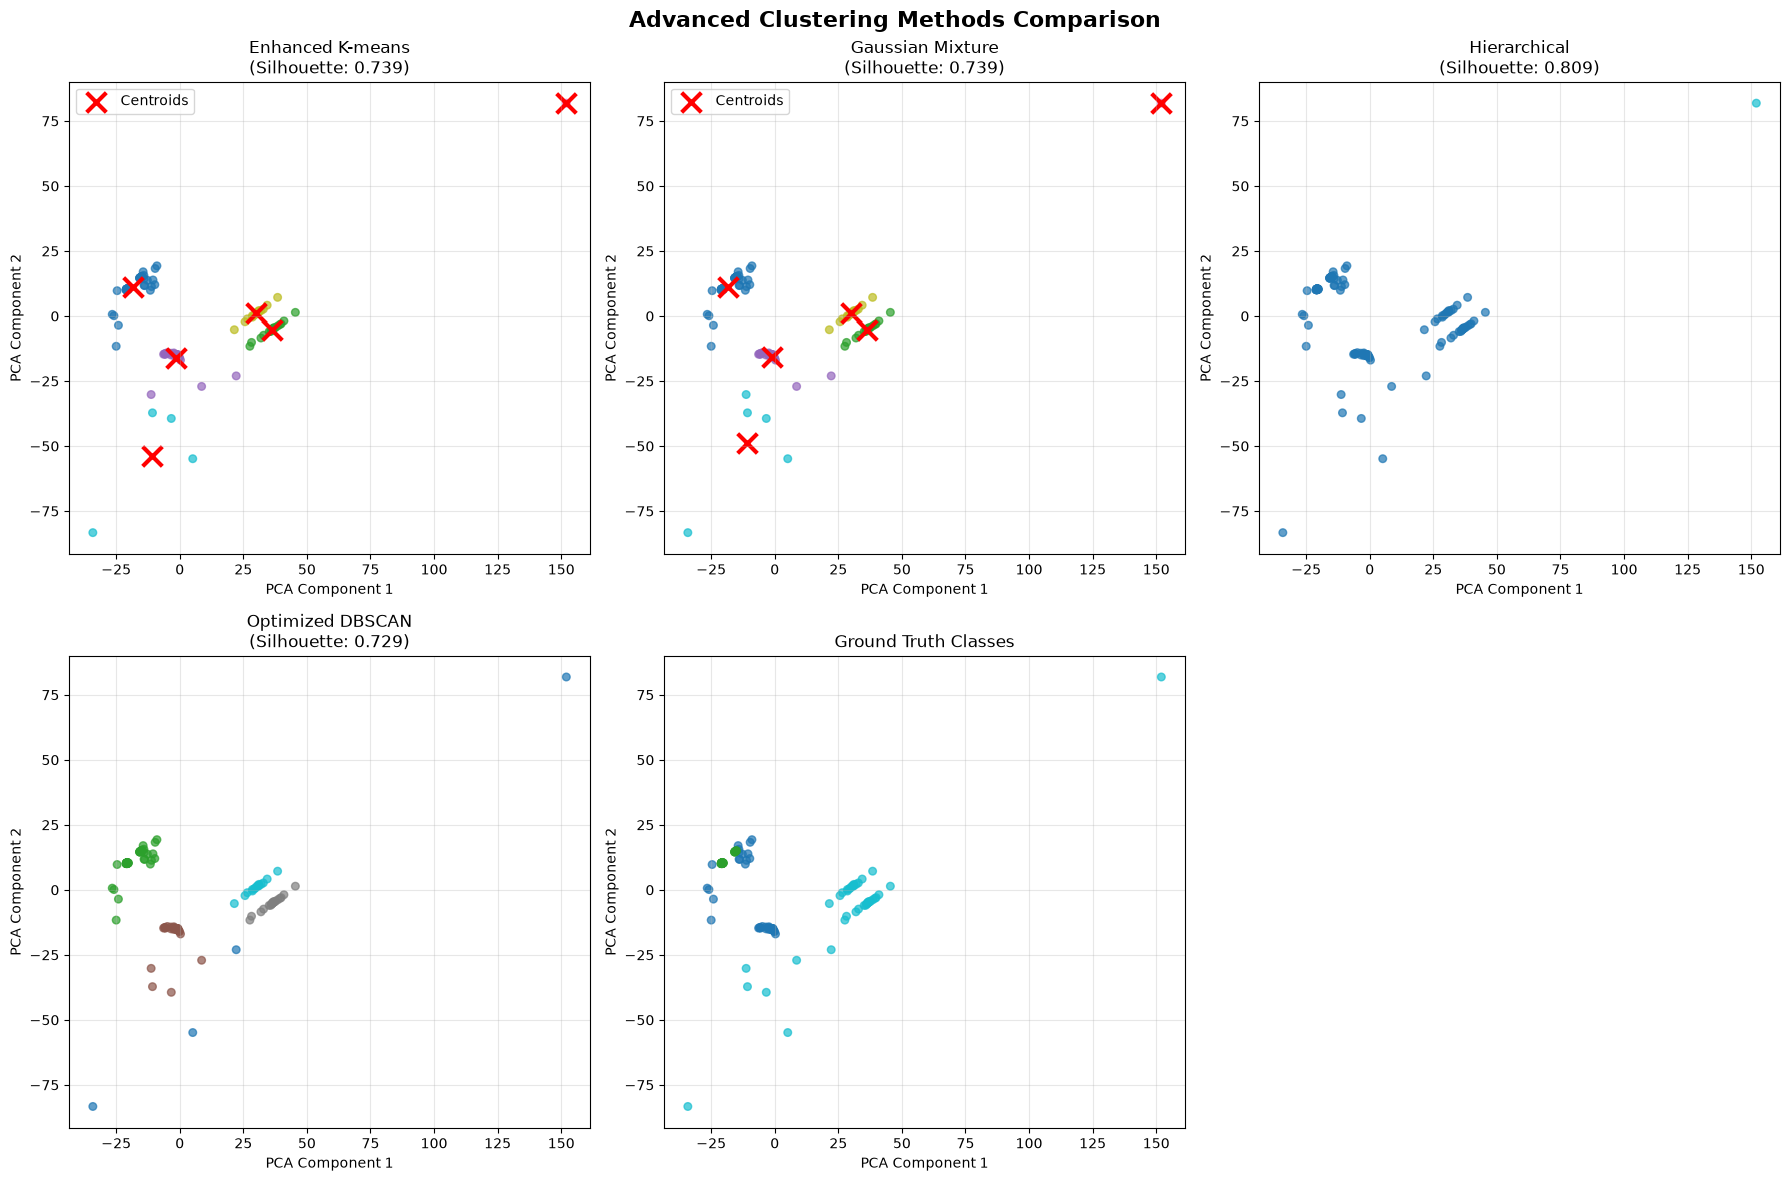


🎨 Advanced Visualizations Complete!


In [17]:
# ============================================================
# ADVANCED VISUALIZATION: CLUSTER COMPARISON WITH CENTERS
# ============================================================

# Import advanced visualization utilities
from src.clustering_visualization import AdvancedClusteringVisualizer

if advanced_results is not None and "clustering_data" in locals():
    print("Creating Advanced Clustering Comparison Visualization...")

    # Initialize advanced visualizer
    advanced_visualizer = AdvancedClusteringVisualizer()

    # Create comprehensive advanced visualizations showing cluster centers and ground truth
    advanced_visualizer.create_advanced_visualizations(
        clustering_data=clustering_data,
        advanced_results=advanced_results,
        original_results=(
            {"kmeans": kmeans_results} if "kmeans_results" in locals() else None
        ),
    )

else:
    print("❌ Advanced results not available. Run the advanced clustering cell first.")

### **Hungarian Algorithm for Clustering Accuracy**

**Problem**: How to fairly compare clustering results with ground truth when cluster labels are arbitrary?

**Solution**: The **Hungarian Algorithm** finds the optimal assignment between predicted clusters and true classes.

**Mathematical Foundation:**

Given a **cost matrix** $C$ where $C_{ij}$ represents the cost of assigning true class $i$ to predicted cluster $j$:

$$\text{Minimize: } \sum_{i,j} C_{ij} \cdot x_{ij}$$

Subject to:
- $\sum_j x_{ij} = 1$ (each true class assigned to exactly one cluster)
- $\sum_i x_{ij} = 1$ (each cluster assigned to exactly one true class)  
- $x_{ij} \in \{0,1\}$ (binary assignment)

**For Clustering Accuracy:**
- $C_{ij} = -\text{count}_{ij}$ (negative because we want to **maximize** matches)
- $\text{count}_{ij}$ = number of samples with true class $i$ in predicted cluster $j$

**Algorithm Steps:**
1. **Build confusion matrix**: Count samples for each (true_class, predicted_cluster) pair
2. **Apply Hungarian algorithm**: Find optimal assignment that maximizes total matches
3. **Calculate accuracy**: $\text{Accuracy} = \frac{\text{Total Optimal Matches}}{\text{Total Samples}}$

**Why Use This?**
- **Fair comparison**: Handles arbitrary cluster labels (cluster 0 might correspond to class 3)
- **Optimal assignment**: Guarantees best possible accuracy for any label permutation
- **Robust metric**: Works even when number of clusters ≠ number of true classes

In [18]:
# ============================================================
# CLUSTERING ACCURACY EVALUATION
# ============================================================

# Import the evaluation function
from src.clustering_utils import evaluate_clustering_accuracy

if advanced_results is not None and "clustering_data" in locals():
    # Prepare clustering results for evaluation
    evaluation_methods = {}

    # Add advanced clustering results
    for method_key, method_result in advanced_results.items():
        if method_result is not None:
            evaluation_methods[method_key.replace("_", " ").title()] = method_result

    # Add K-means results (scaled)
    if "kmeans_results" in locals() and kmeans_results is not None:
        evaluation_methods["K-means (Scaled)"] = kmeans_results

    # Add K-means PCA results
    if "kmeans_results_pca" in locals() and kmeans_results_pca is not None:
        evaluation_methods["K-means (PCA 50D)"] = kmeans_results_pca

    # Run comprehensive accuracy evaluation
    accuracy_results = evaluate_clustering_accuracy(
        y_true=clustering_data["y_labels"], clustering_results=evaluation_methods
    )

    print(f"\n🎯 Evaluation complete! {len(accuracy_results)} methods evaluated.")

else:
    print("❌ Advanced results not available. Run the advanced clustering cell first.")

🎯 Evaluating Clustering Accuracy Against Ground Truth
📊 Clustering Method Accuracy Results:
--------------------------------------------------
   • Enhanced Kmeans          : 0.701 (70.1%) | Clusters: 6
   • Gmm                      : 0.701 (70.1%) | Clusters: 6
   • Hierarchical             : 0.354 (35.4%) | Clusters: 2
   • Optimized Dbscan         : 0.701 (70.1%) | Clusters: 5
   • K-means (Scaled)         : 0.701 (70.1%) | Clusters: 6
   • K-means (PCA 50D)        : 0.701 (70.1%) | Clusters: 6

🏆 Best Performing Method: Enhanced Kmeans (70.1%)
📊 Ground Truth Classes: 3 | Total Samples: 144

✅ Accuracy evaluation complete!

🎯 Evaluation complete! 6 methods evaluated.


2026-11-05 17:27:06,427 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


2026-11-05 17:27:06,427 | INFO | matplotlib.category | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


🎨 Running Complete Clustering Analysis Visualization Suite
🎨 Running Complete Clustering Analysis Visualization Suite
📊 1. Generating Data Overview...


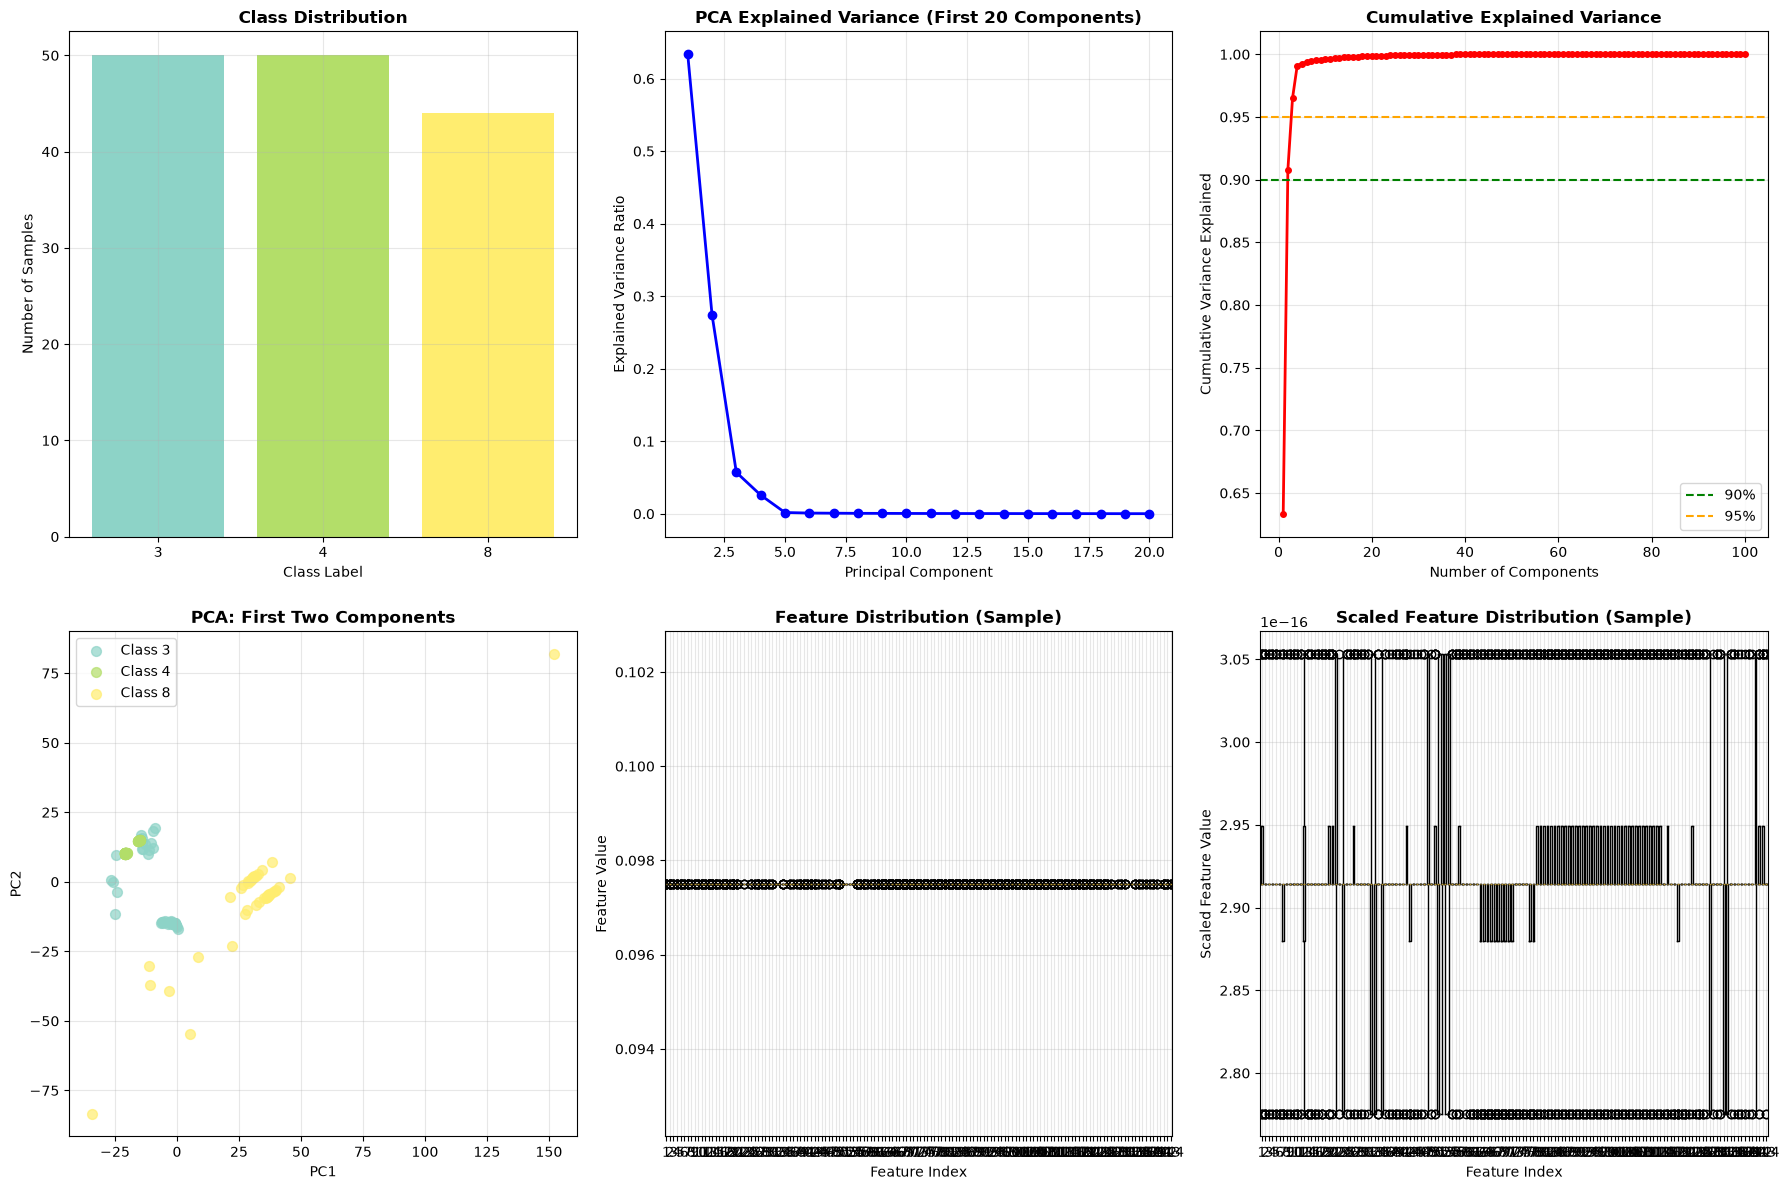

📈 4. Generating Performance Summary...


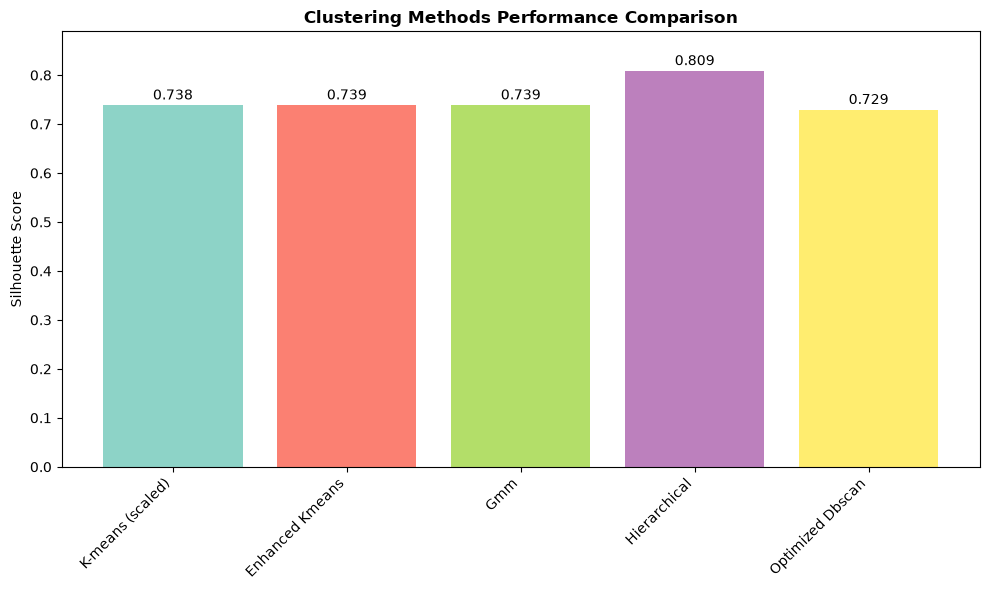

🎯 5. Generating Accuracy Summary...


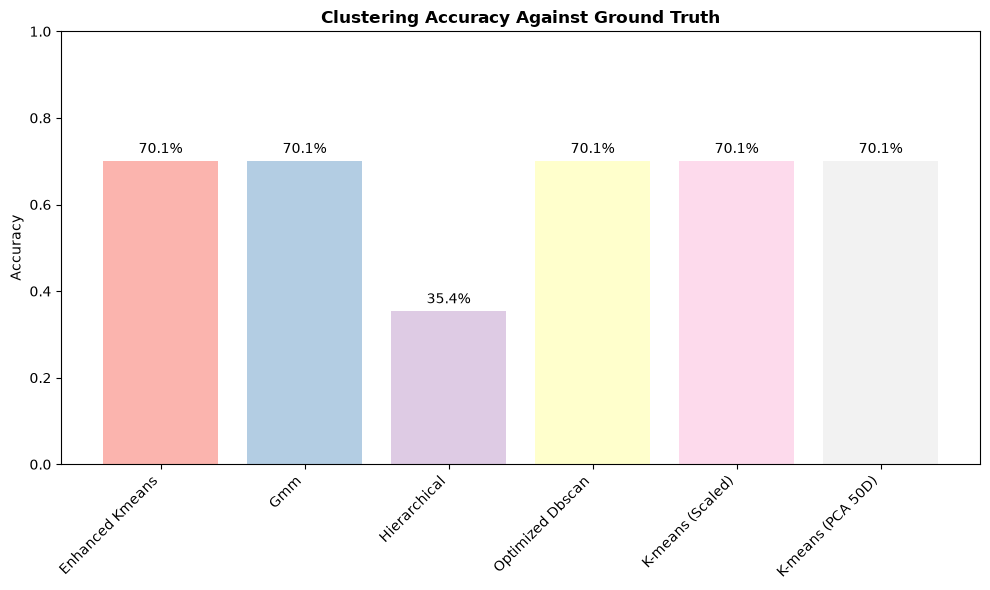


🎉 Visualization Suite Complete!
   📊 Generated 3 visualization(s)
-----------------------------------------------------------------


In [19]:
# ============================================================
# COMPLETE CLUSTERING ANALYSIS VISUALIZATION SUITE
# ============================================================

print("🎨 Running Complete Clustering Analysis Visualization Suite")
print("=" * 65)

# Use the extracted visualization orchestration method
visualizer.clustering_analysis_suite(
    clustering_data=clustering_data,
    kmeans_results=kmeans_results,  # Scaled K-means results
    advanced_results=advanced_results,
    accuracy_results=accuracy_results if "accuracy_results" in locals() else None,
)

## 📖 Guided exercise (book, Appendix E — exercise 6)

Replace the input space of this notebook by the **latent space of the autoencoder** trained in notebook 3 and recompute the silhouette and the adjusted Rand index. Compare the values with those of the book's Chapter 12 (latent-space quality table).

> 📖 *Lopes et al. (2026), Appendix E — "Roteiro prático com o repositório 3W"* ([DOI 10.5281/zenodo.22306796](https://doi.org/10.5281/zenodo.22306796)).